# MLP


Goal: train an MLP to classify **CIFAR-100** images (32×32 colour images, 100 classes). The model may only use `nn.Flatten`, `nn.Linear`, activation functions and `nn.Dropout`.

**How the experiments are organised**
1. Start from a simple baseline (2 hidden layers × 512 neurons, ReLU, SGD with lr = 0.01).
2. Run one sweep per idea: optimizer → learning rate / scheduler → architecture → activation function → dropout → data augmentation.
3. Inside a sweep, every run changes **only one thing** compared with the current best setup. The seed, batch size and number of epochs (20) never change during the sweeps.
4. The winner of each sweep is carried into the next sweep.
5. Every run has its own cell, so no result gets overwritten.

Runs are compared by **test accuracy after the last epoch**.

## 1. Load Libraries

In [1]:
import time

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt

## 2. Create Data Loader
- `train=True` loads the 50,000 training images and `train=False` loads the 10,000 test images.
- `Normalize` scales each colour channel to mean 0 and std 1, using the mean and std of the CIFAR-100 training set. The cell computes both from the training images and rounds them to 4 decimals. This is preprocessing, not augmentation, so every run uses it.
- The training data is shuffled every epoch.

In [1]:
## Mean and std of each colour channel, computed from every pixel of the 50,000 training images ##
raw_images = datasets.CIFAR100(root="data", train=True, download=True).data   # [50000, 32, 32, 3], values 0..255
mean = tuple((raw_images.mean(axis=(0, 1, 2)) / 255).round(4).tolist())       # / 255 because ToTensor scales pixels to 0..1
std = tuple((raw_images.std(axis=(0, 1, 2)) / 255).round(4).tolist())
print("Mean:", mean)
print("Std: ", std)

basic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

## Create the dataset ##
training_data = datasets.CIFAR100(root="data", train=True,
                                  download=True, transform=basic_transform)
test_data = datasets.CIFAR100(root="data", train=False,
                              download=True, transform=basic_transform)

## Create data loader ##
batch_size = 128
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

classes = training_data.classes
print("Training images:", len(training_data))
print("Test images:", len(test_data))
print("Number of classes:", len(classes))

Mean: (0.5071, 0.4865, 0.4409)
Std:  (0.2673, 0.2564, 0.2762)
Training images: 50000
Test images: 10000
Number of classes: 100


## 3. Sample Data Visualization

Shape of X [N, C, H, W]: torch.Size([128, 3, 32, 32])
Shape of Y: torch.Size([128])


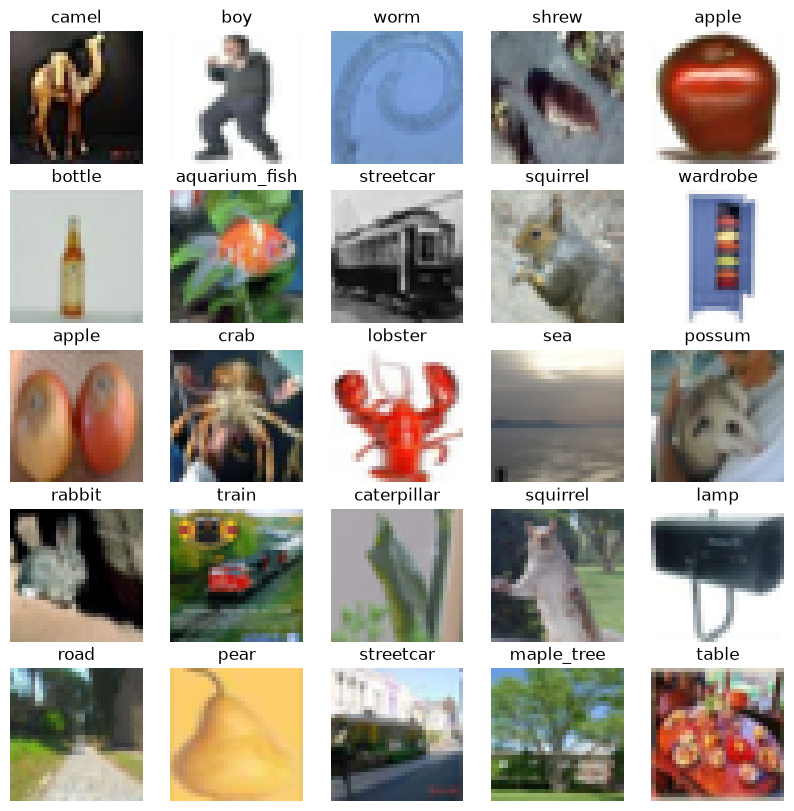

In [3]:
for data in train_dataloader:
    break

X = data[0]
Y = data[1]
print("Shape of X [N, C, H, W]:", X.shape)
print("Shape of Y:", Y.shape)

plt.figure(figsize=(10,10))
for i in range(25):
    img = X[i].permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)   # [C,H,W] -> [H,W,C], undo Normalize
    plt.subplot(5,5,i+1)
    plt.imshow(img.clamp(0, 1))
    plt.title(classes[Y[i]])
    plt.axis("off")
plt.show()

Training images per class: min 500, max 500
Test images per class:     min 100, max 100


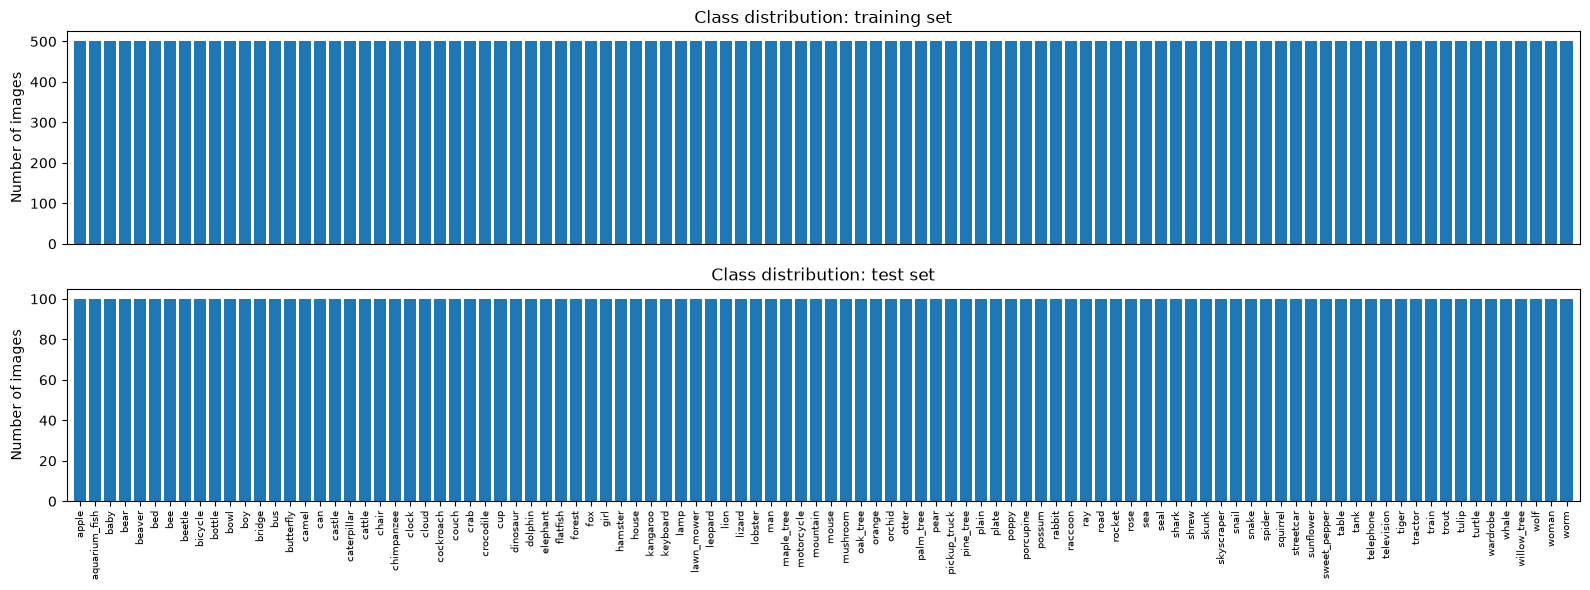

In [1]:
# class distribution: number of images per class in the training set and in the test set
train_counts = torch.bincount(torch.tensor(training_data.targets), minlength=100)
test_counts = torch.bincount(torch.tensor(test_data.targets), minlength=100)
print("Training images per class: min %d, max %d" % (train_counts.min(), train_counts.max()))
print("Test images per class:     min %d, max %d" % (test_counts.min(), test_counts.max()))

plt.figure(figsize=(16,6))
plt.subplot(2,1,1)
plt.bar(classes, train_counts)
plt.xticks([])
plt.margins(x=0.005)
plt.ylabel("Number of images")
plt.title("Class distribution: training set")
plt.subplot(2,1,2)
plt.bar(classes, test_counts)
plt.xticks(rotation=90, fontsize=7)
plt.margins(x=0.005)
plt.ylabel("Number of images")
plt.title("Class distribution: test set")
plt.tight_layout()
plt.show()

CIFAR-100 is perfectly balanced: every class has 500 training images and 100 test images.

## 4. Defining MLP Model
- Input layer: a 32×32×3 image, flattened to 3072 numbers.
- Hidden layers: `Linear` → activation (→ `Dropout`), one block per entry in `hidden_sizes`.
- Output layer: 100 logits, one per class.

The layer sizes, activation and dropout are arguments, so each experiment can change one of them without editing the class.

In [ ]:
class MLP(nn.Module):
    # define the structure of the model
    def __init__(self, hidden_sizes=(512, 512), activation=nn.ReLU, dropout=0.0):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()

        layers = []
        in_size = 32*32*3                            # input: 3072 pixel values
        for size in hidden_sizes:
            layers.append(nn.Linear(in_size, size))  # hidden layer
            layers.append(activation())              # non-linear activation
            if dropout > 0:
                layers.append(nn.Dropout(dropout))   # 3
            in_size = size
        layers.append(nn.Linear(in_size, 100))       # output layer: 100 classes
        self.layers = nn.Sequential(*layers)

    # define data passing flow
    def forward(self, x):
        x = self.flatten(x)
        logits = self.layers(x)
        return logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = MLP()
print(model)
print("Parameters:", count_parameters(model))

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=100, bias=True)
  )
)
Parameters: 1887332


## 5. Defining the TRAIN operation
For each batch: load it, pass it through the model, compute the loss, backpropagate and update the weights.

The function also returns the average training loss and accuracy, so we can compare them with the test numbers and spot overfitting.

In [5]:
def train(dataloader, model, loss_fn, optimizer, device):
    model.train() # set model to train mode
    total_loss = 0
    correct = 0
    for X, y in dataloader:
        # send data to GPU or CPU
        X = X.to(device)
        y = y.to(device)

        # feed the data to model
        pred = model(X)
        # compute the loss
        loss = loss_fn(pred, y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()  # compute the gradients
        optimizer.step() # update the parameters/weights

        total_loss += loss.item()
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    return total_loss / len(dataloader), correct / len(dataloader.dataset)

## 6. Defining the TEST operation
Same as training except: `model.eval()` (turns Dropout off), `torch.no_grad()` (no gradients), and no weight updates.

The number of correct predictions is divided by the number of test images. The last batch is smaller than `batch_size`, so dividing by `num_batches * batch_size` would count images that don't exist.

In [6]:
def test(dataloader, model, loss_fn, device):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    return test_loss / len(dataloader), correct / len(dataloader.dataset)

## 7. Experiment Helpers
- `run_experiment` trains a model for `epochs` epochs, tests it after every epoch and stores the accuracy history in `results[sweep][label]`.
- `compare` prints and plots every run of one sweep.
- Every experiment cell calls `torch.manual_seed(0)` first, so every run starts from the same random weights and sees the data in the same order.

In [7]:
# get cpu or gpu for training
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using %s device" % device)

loss_fn = nn.CrossEntropyLoss()
epochs = 20
results = {}   # sweep name -> {run label -> accuracy history}

def run_experiment(sweep, label, model, optimizer, train_dataloader, scheduler=None):
    print("%s | %s | %d parameters" % (sweep, label, count_parameters(model)))
    history = {"train_acc": [], "test_acc": []}
    start = time.time()
    for t in range(epochs):
        train_loss, train_acc = train(train_dataloader, model, loss_fn, optimizer, device)
        test_loss, test_acc = test(test_dataloader, model, loss_fn, device)
        if scheduler is not None:
            scheduler.step()   # update the learning rate once per epoch
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        if (t+1) % 5 == 0:
            print("Epoch %2d | train loss %.4f, acc %.4f | test loss %.4f, acc %.4f"
                  % (t+1, train_loss, train_acc, test_loss, test_acc))
    print("Final test accuracy: %.4f  (%.0fs)" % (test_acc, time.time() - start))
    results.setdefault(sweep, {})[label] = history

def compare(sweep):
    runs = results[sweep]
    best = max(runs, key=lambda label: runs[label]["test_acc"][-1])
    for label, history in runs.items():
        print("%-32s final train acc %.4f | final test acc %.4f%s"
              % (label, history["train_acc"][-1], history["test_acc"][-1],
                 "   <-- best" if label == best else ""))

    plt.figure(figsize=(14,4))
    for i, key in enumerate(["test_acc", "train_acc"]):
        plt.subplot(1,2,i+1)
        for label, history in runs.items():
            plt.plot(range(1, len(history[key])+1), history[key], label=label)
        plt.title("%s: %s" % (sweep, "test accuracy" if key == "test_acc" else "train accuracy"))
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
    plt.show()

Using cuda device


## 8. Baseline
, adapted to CIFAR-100: 3072 → 512 → 512 → 100, ReLU, no dropout, no augmentation, SGD with lr = 0.01 and no scheduler.

In [8]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)
run_experiment("Baseline", "SGD, lr=0.01", model, optimizer, train_dataloader)

Baseline | SGD, lr=0.01 | 1887332 parameters
Epoch  5 | train loss 3.6382, acc 0.1574 | test loss 3.6473, acc 0.1548
Epoch 10 | train loss 3.3547, acc 0.2075 | test loss 3.4501, acc 0.1911
Epoch 15 | train loss 3.1645, acc 0.2432 | test loss 3.3281, acc 0.2155
Epoch 20 | train loss 2.9957, acc 0.2771 | test loss 3.2412, acc 0.2362
Final test accuracy: 0.2362  (64s)


## 9. Sweep 1: Optimizer
**Changed:** the optimizer.
**Fixed:** 2 × 512 hidden layers, ReLU, no dropout, no augmentation, no scheduler.

The adaptive optimizers (RMSprop, Adam, AdamW) take much bigger steps than SGD at the same learning rate. Each optimizer therefore uses its usual learning rate: 0.01 for SGD and 0.001 for the adaptive ones. Sweep 2 then tunes the learning rate of the winner.

In [9]:
# plain SGD (lr=0.01) is the baseline run, so reuse it
results["Optimizer"] = {"SGD, lr=0.01": results["Baseline"]["SGD, lr=0.01"]}

In [10]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)
run_experiment("Optimizer", "SGD+momentum, lr=0.01", model, optimizer, train_dataloader)

Optimizer | SGD+momentum, lr=0.01 | 1887332 parameters
Epoch  5 | train loss 2.8705, acc 0.2913 | test loss 3.1666, acc 0.2489
Epoch 10 | train loss 2.1799, acc 0.4346 | test loss 3.2138, acc 0.2706
Epoch 15 | train loss 1.5014, acc 0.5921 | test loss 3.7616, acc 0.2576
Epoch 20 | train loss 0.9342, acc 0.7340 | test loss 4.5644, acc 0.2550
Final test accuracy: 0.2550  (73s)


In [11]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
run_experiment("Optimizer", "RMSprop, lr=0.001", model, optimizer, train_dataloader)

Optimizer | RMSprop, lr=0.001 | 1887332 parameters
Epoch  5 | train loss 2.7957, acc 0.3026 | test loss 3.4260, acc 0.2220
Epoch 10 | train loss 2.0374, acc 0.4615 | test loss 3.8769, acc 0.2314
Epoch 15 | train loss 1.4491, acc 0.6054 | test loss 4.8553, acc 0.2243
Epoch 20 | train loss 1.1025, acc 0.6909 | test loss 6.0244, acc 0.2218
Final test accuracy: 0.2218  (65s)


In [12]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
run_experiment("Optimizer", "Adam, lr=0.001", model, optimizer, train_dataloader)

Optimizer | Adam, lr=0.001 | 1887332 parameters
Epoch  5 | train loss 2.7857, acc 0.3055 | test loss 3.3143, acc 0.2336
Epoch 10 | train loss 2.0210, acc 0.4625 | test loss 3.7694, acc 0.2361
Epoch 15 | train loss 1.3666, acc 0.6177 | test loss 4.7778, acc 0.2277
Epoch 20 | train loss 0.9922, acc 0.7141 | test loss 5.8735, acc 0.2288
Final test accuracy: 0.2288  (65s)


In [13]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)   # Adam + weight decay (default 0.01)
run_experiment("Optimizer", "AdamW, lr=0.001", model, optimizer, train_dataloader)

Optimizer | AdamW, lr=0.001 | 1887332 parameters
Epoch  5 | train loss 2.7931, acc 0.3033 | test loss 3.2806, acc 0.2356
Epoch 10 | train loss 2.0535, acc 0.4535 | test loss 3.7368, acc 0.2339
Epoch 15 | train loss 1.4072, acc 0.6087 | test loss 4.5767, acc 0.2322
Epoch 20 | train loss 1.0069, acc 0.7120 | test loss 5.6707, acc 0.2264
Final test accuracy: 0.2264  (64s)


SGD, lr=0.01                     final train acc 0.2771 | final test acc 0.2362
SGD+momentum, lr=0.01            final train acc 0.7340 | final test acc 0.2550   <-- best
RMSprop, lr=0.001                final train acc 0.6909 | final test acc 0.2218
Adam, lr=0.001                   final train acc 0.7141 | final test acc 0.2288
AdamW, lr=0.001                  final train acc 0.7120 | final test acc 0.2264


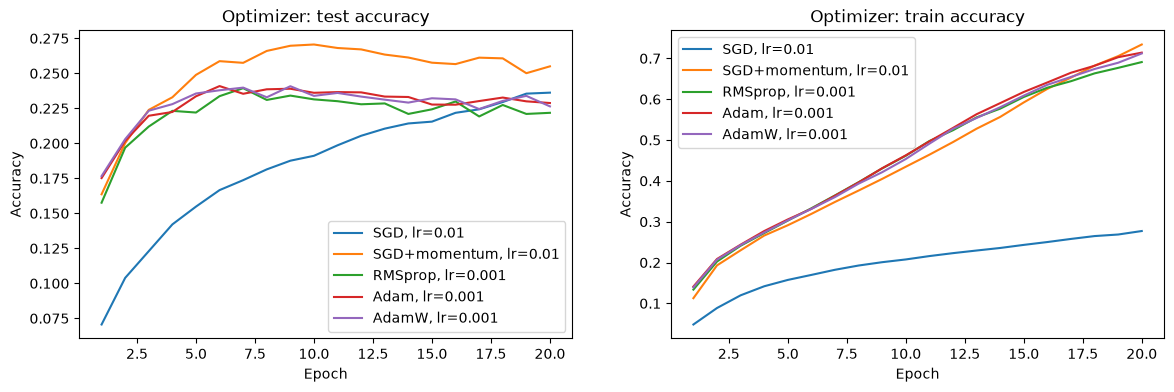

In [14]:
compare("Optimizer")

**Result:** SGD with momentum gives the best final test accuracy (25.5%).
- Plain SGD learns slowly: after 20 epochs train and test accuracy are both still rising.
- Every other optimizer overfits: train accuracy reaches ~70% while test accuracy peaks around epoch 5–10 and then drops (test loss goes up).
- Adam, AdamW and RMSprop overfit the fastest and end at 22–23%.

→ **Carry forward: SGD + momentum (0.9).**

## 10. Sweep 2a: Learning Rate
**Changed:** the learning rate.
**Fixed:** SGD + momentum 0.9, 2 × 512 hidden layers, ReLU, no dropout, no augmentation, no scheduler.

In [17]:
# lr=0.01 is the winning run from Sweep 1, so reuse it
results["Learning rate"] = {"lr=0.01": results["Optimizer"]["SGD+momentum, lr=0.01"]}

In [18]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9)
run_experiment("Learning rate", "lr=0.1", model, optimizer, train_dataloader)

Learning rate | lr=0.1 | 1887332 parameters
Epoch  5 | train loss 4.0545, acc 0.0964 | test loss 4.1316, acc 0.0869
Epoch 10 | train loss 4.0130, acc 0.1053 | test loss 4.1613, acc 0.0870
Epoch 15 | train loss 3.9506, acc 0.1198 | test loss 4.2181, acc 0.1017
Epoch 20 | train loss 3.9313, acc 0.1282 | test loss 4.2873, acc 0.0939
Final test accuracy: 0.0939  (64s)


In [19]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
run_experiment("Learning rate", "lr=0.05", model, optimizer, train_dataloader)

Learning rate | lr=0.05 | 1887332 parameters
Epoch  5 | train loss 3.2479, acc 0.2255 | test loss 3.5856, acc 0.1843
Epoch 10 | train loss 2.9906, acc 0.2775 | test loss 3.8226, acc 0.1814
Epoch 15 | train loss 2.7955, acc 0.3246 | test loss 4.2111, acc 0.1787
Epoch 20 | train loss 2.6799, acc 0.3580 | test loss 4.5257, acc 0.1731
Final test accuracy: 0.1731  (65s)


In [20]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
run_experiment("Learning rate", "lr=0.005", model, optimizer, train_dataloader)

Learning rate | lr=0.005 | 1887332 parameters
Epoch  5 | train loss 3.0934, acc 0.2517 | test loss 3.2373, acc 0.2325
Epoch 10 | train loss 2.5696, acc 0.3582 | test loss 3.1211, acc 0.2615
Epoch 15 | train loss 2.0785, acc 0.4630 | test loss 3.2275, acc 0.2674
Epoch 20 | train loss 1.5776, acc 0.5809 | test loss 3.4706, acc 0.2690
Final test accuracy: 0.2690  (66s)


In [21]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
run_experiment("Learning rate", "lr=0.001", model, optimizer, train_dataloader)

Learning rate | lr=0.001 | 1887332 parameters
Epoch  5 | train loss 3.6444, acc 0.1563 | test loss 3.6479, acc 0.1560
Epoch 10 | train loss 3.3575, acc 0.2059 | test loss 3.4492, acc 0.1914
Epoch 15 | train loss 3.1656, acc 0.2440 | test loss 3.3272, acc 0.2134
Epoch 20 | train loss 2.9978, acc 0.2769 | test loss 3.2373, acc 0.2348
Final test accuracy: 0.2348  (66s)


lr=0.01                          final train acc 0.7340 | final test acc 0.2550
lr=0.1                           final train acc 0.1282 | final test acc 0.0939
lr=0.05                          final train acc 0.3580 | final test acc 0.1731
lr=0.005                         final train acc 0.5809 | final test acc 0.2690   <-- best
lr=0.001                         final train acc 0.2769 | final test acc 0.2348


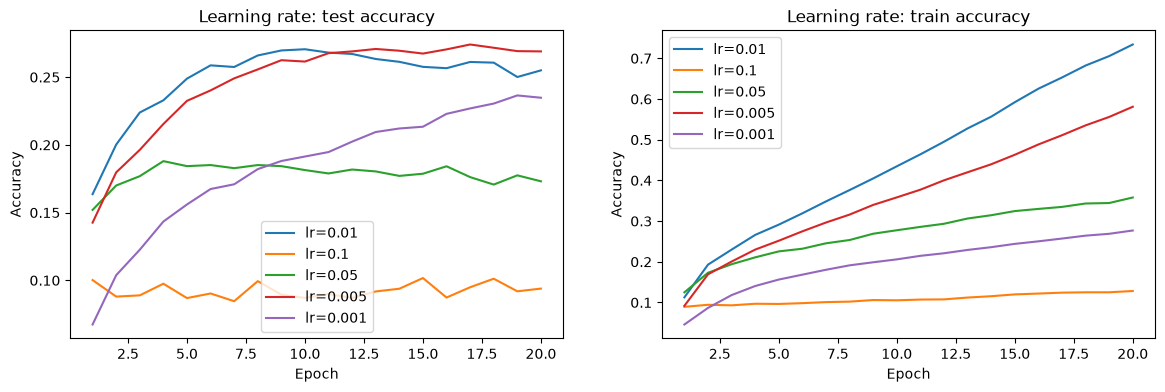

In [22]:
compare("Learning rate")

**Result:** lr = 0.005 gives the best final test accuracy (26.9%).
- lr = 0.1 and 0.05 are too large: the updates overshoot, so the loss decreases slowly and test accuracy stays low (9% and 17%).
- lr = 0.001 is too small: after 20 epochs the model is still underfitting (train acc 28%).
- lr = 0.01 learns fast but overfits after ~10 epochs. lr = 0.005 overfits more slowly, so it ends higher.

→ **Carry forward: lr = 0.005.**

## 11. Sweep 2b: Learning Rate Scheduler
**Changed:** how the learning rate changes during training (the scheduler is stepped once per epoch).
**Fixed:** SGD + momentum 0.9, start lr = 0.005, 2 × 512 hidden layers, ReLU, no dropout, no augmentation.

- `StepLR`: multiply the lr by 0.1 after 10 epochs.
- `ExponentialLR`: multiply the lr by 0.9 every epoch.
- `CosineAnnealingLR`: decrease the lr along a cosine curve, from 0.005 to 0 at the last epoch.

In [23]:
# "no scheduler" is the winning run from Sweep 2a, so reuse it
results["Scheduler"] = {"no scheduler": results["Learning rate"]["lr=0.005"]}

In [24]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Scheduler", "StepLR", model, optimizer, train_dataloader, scheduler)

Scheduler | StepLR | 1887332 parameters
Epoch  5 | train loss 3.0934, acc 0.2517 | test loss 3.2373, acc 0.2325
Epoch 10 | train loss 2.5696, acc 0.3582 | test loss 3.1211, acc 0.2615
Epoch 15 | train loss 2.2197, acc 0.4466 | test loss 3.0263, acc 0.2880
Epoch 20 | train loss 2.1413, acc 0.4646 | test loss 3.0306, acc 0.2892
Final test accuracy: 0.2892  (65s)


In [25]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)
run_experiment("Scheduler", "ExponentialLR", model, optimizer, train_dataloader, scheduler)

Scheduler | ExponentialLR | 1887332 parameters
Epoch  5 | train loss 3.1357, acc 0.2460 | test loss 3.2752, acc 0.2243
Epoch 10 | train loss 2.7476, acc 0.3240 | test loss 3.1312, acc 0.2539
Epoch 15 | train loss 2.5053, acc 0.3784 | test loss 3.0774, acc 0.2706
Epoch 20 | train loss 2.3481, acc 0.4144 | test loss 3.0585, acc 0.2797
Final test accuracy: 0.2797  (66s)


In [26]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
run_experiment("Scheduler", "CosineAnnealingLR", model, optimizer, train_dataloader, scheduler)

Scheduler | CosineAnnealingLR | 1887332 parameters
Epoch  5 | train loss 3.0953, acc 0.2520 | test loss 3.2407, acc 0.2326
Epoch 10 | train loss 2.5968, acc 0.3558 | test loss 3.0991, acc 0.2621
Epoch 15 | train loss 2.2471, acc 0.4374 | test loss 3.0484, acc 0.2827
Epoch 20 | train loss 2.1113, acc 0.4751 | test loss 3.0291, acc 0.2878
Final test accuracy: 0.2878  (65s)


no scheduler                     final train acc 0.5809 | final test acc 0.2690
StepLR                           final train acc 0.4646 | final test acc 0.2892   <-- best
ExponentialLR                    final train acc 0.4144 | final test acc 0.2797
CosineAnnealingLR                final train acc 0.4751 | final test acc 0.2878


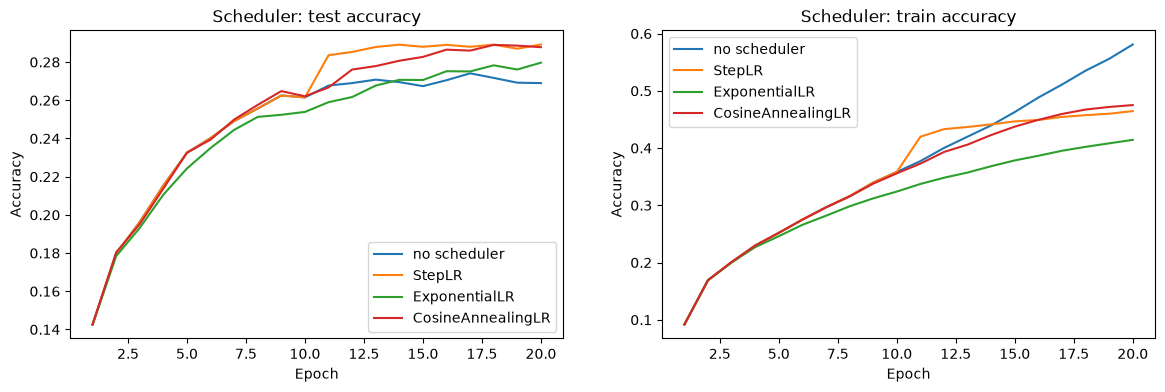

In [27]:
compare("Scheduler")

**Result:** every scheduler beats a constant learning rate (26.9%). StepLR is best (28.9%), with CosineAnnealingLR almost tied (28.8%).
- Lowering the lr late in training lets the model settle into a minimum instead of continuing to memorise the training set: train accuracy is lower (~46% vs 58%), yet test accuracy is higher and test loss stops rising.
- ExponentialLR lowers the lr too early, so it learns a bit less.

→ **Carry forward: StepLR (lr × 0.1 after 10 epochs).**

## 12. Sweep 3a: Architecture (number of hidden layers)
**Changed:** the number of hidden layers, each with 512 neurons.
**Fixed:** ReLU, no dropout, no augmentation, SGD + momentum 0.9, lr = 0.005, StepLR.

In [28]:
# 2 hidden layers is the winning run from Sweep 2b, so reuse it
results["Depth"] = {"2 x 512": results["Scheduler"]["StepLR"]}

In [29]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Depth", "1 x 512", model, optimizer, train_dataloader, scheduler)

Depth | 1 x 512 | 1624676 parameters
Epoch  5 | train loss 2.9775, acc 0.2818 | test loss 3.2574, acc 0.2346
Epoch 10 | train loss 2.4837, acc 0.3861 | test loss 3.2256, acc 0.2536
Epoch 15 | train loss 2.1336, acc 0.4853 | test loss 3.1053, acc 0.2798
Epoch 20 | train loss 2.0711, acc 0.5004 | test loss 3.1143, acc 0.2786
Final test accuracy: 0.2786  (67s)


In [30]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Depth", "3 x 512", model, optimizer, train_dataloader, scheduler)

Depth | 3 x 512 | 2149988 parameters
Epoch  5 | train loss 3.2489, acc 0.2186 | test loss 3.3323, acc 0.2056
Epoch 10 | train loss 2.7382, acc 0.3159 | test loss 3.1013, acc 0.2589
Epoch 15 | train loss 2.4014, acc 0.3904 | test loss 3.0170, acc 0.2810
Epoch 20 | train loss 2.3188, acc 0.4088 | test loss 3.0115, acc 0.2887
Final test accuracy: 0.2887  (66s)


In [31]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[512, 512, 512, 512], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Depth", "4 x 512", model, optimizer, train_dataloader, scheduler)

Depth | 4 x 512 | 2412644 parameters
Epoch  5 | train loss 3.4295, acc 0.1801 | test loss 3.4480, acc 0.1811
Epoch 10 | train loss 2.9239, acc 0.2737 | test loss 3.1811, acc 0.2387
Epoch 15 | train loss 2.6020, acc 0.3408 | test loss 3.0786, acc 0.2660
Epoch 20 | train loss 2.5139, acc 0.3575 | test loss 3.0647, acc 0.2726
Final test accuracy: 0.2726  (69s)


2 x 512                          final train acc 0.4646 | final test acc 0.2892   <-- best
1 x 512                          final train acc 0.5004 | final test acc 0.2786
3 x 512                          final train acc 0.4088 | final test acc 0.2887
4 x 512                          final train acc 0.3575 | final test acc 0.2726


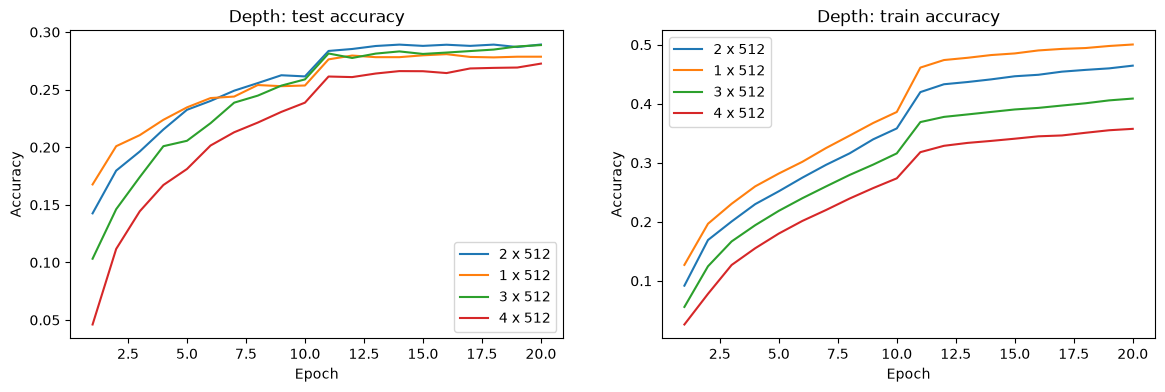

In [32]:
compare("Depth")

**Result:** 2 hidden layers is best (28.9%), with 3 layers almost tied (28.9%).
- 1 layer learns the training set fastest but generalises a bit worse (27.9%).
- 3 and 4 layers learn more slowly. With 20 epochs, and the lr dropped after epoch 10, the 4-layer net is still underfitting (train acc 36%).

→ **Carry forward: 2 hidden layers.**

## 13. Sweep 3b: Architecture (neurons per hidden layer)
**Changed:** the number of neurons in each of the 2 hidden layers.
**Fixed:** 2 hidden layers, ReLU, no dropout, no augmentation, SGD + momentum 0.9, lr = 0.005, StepLR.

In [33]:
# 512 neurons is the winning run from Sweep 3a, so reuse it
results["Width"] = {"2 x 512": results["Depth"]["2 x 512"]}

In [34]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[256, 256], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Width", "2 x 256", model, optimizer, train_dataloader, scheduler)

Width | 2 x 256 | 878180 parameters
Epoch  5 | train loss 3.1596, acc 0.2409 | test loss 3.2914, acc 0.2130
Epoch 10 | train loss 2.7070, acc 0.3270 | test loss 3.1388, acc 0.2578
Epoch 15 | train loss 2.4139, acc 0.3969 | test loss 3.0677, acc 0.2784
Epoch 20 | train loss 2.3537, acc 0.4101 | test loss 3.0702, acc 0.2816
Final test accuracy: 0.2816  (73s)


In [35]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[1024, 1024], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Width", "2 x 1024", model, optimizer, train_dataloader, scheduler)

Width | 2 x 1024 | 4298852 parameters
Epoch  5 | train loss 3.0466, acc 0.2643 | test loss 3.2066, acc 0.2355
Epoch 10 | train loss 2.4525, acc 0.3815 | test loss 3.0752, acc 0.2696
Epoch 15 | train loss 2.0459, acc 0.4909 | test loss 2.9732, acc 0.2993
Epoch 20 | train loss 1.9492, acc 0.5159 | test loss 2.9781, acc 0.3004
Final test accuracy: 0.3004  (70s)


In [36]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.ReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Width", "2 x 2048", model, optimizer, train_dataloader, scheduler)

Width | 2 x 2048 | 10694756 parameters
Epoch  5 | train loss 2.9830, acc 0.2774 | test loss 3.1816, acc 0.2430
Epoch 10 | train loss 2.3098, acc 0.4157 | test loss 3.0596, acc 0.2782
Epoch 15 | train loss 1.8493, acc 0.5461 | test loss 2.9603, acc 0.3040
Epoch 20 | train loss 1.7370, acc 0.5757 | test loss 2.9731, acc 0.3031
Final test accuracy: 0.3031  (70s)


2 x 512                          final train acc 0.4646 | final test acc 0.2892
2 x 256                          final train acc 0.4101 | final test acc 0.2816
2 x 1024                         final train acc 0.5159 | final test acc 0.3004
2 x 2048                         final train acc 0.5757 | final test acc 0.3031   <-- best


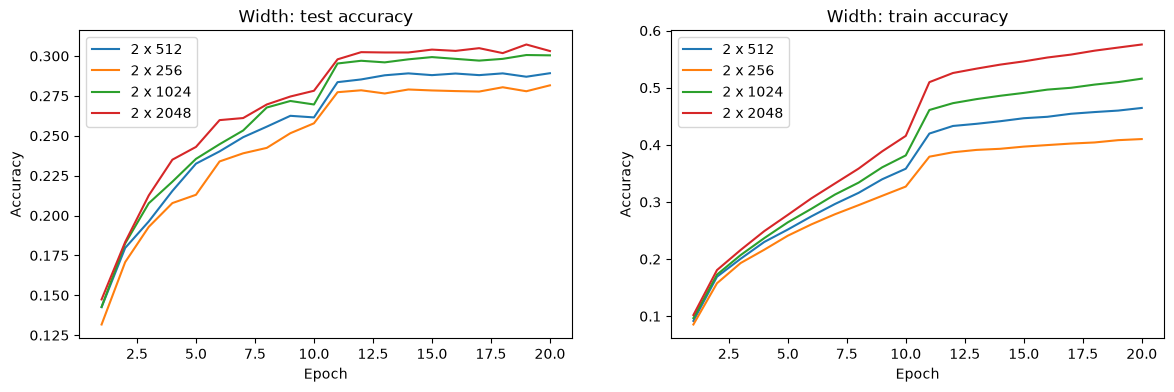

In [37]:
compare("Width")

**Result:** wider layers help. 2 × 2048 is best (30.3%), just ahead of 2 × 1024 (30.0%).
- More neurons give the model more capacity, so both train and test accuracy go up.
- The gain gets smaller with each doubling: +1.1% from 512 → 1024, but only +0.3% from 1024 → 2048.

→ **Carry forward: 2 hidden layers × 2048 neurons.**

## 14. Sweep 4: Activation Function
**Changed:** the non-linear activation after each hidden layer.
**Fixed:** 2 × 2048 hidden layers, no dropout, no augmentation, SGD + momentum 0.9, lr = 0.005, StepLR.

In [38]:
# ReLU is the winning run from Sweep 3b, so reuse it
results["Activation"] = {"ReLU": results["Width"]["2 x 2048"]}

In [39]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.Sigmoid, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Activation", "Sigmoid", model, optimizer, train_dataloader, scheduler)

Activation | Sigmoid | 10694756 parameters
Epoch  5 | train loss 4.0099, acc 0.0847 | test loss 4.0001, acc 0.0884
Epoch 10 | train loss 3.7647, acc 0.1310 | test loss 3.7900, acc 0.1270
Epoch 15 | train loss 3.7081, acc 0.1447 | test loss 3.7458, acc 0.1355
Epoch 20 | train loss 3.6948, acc 0.1473 | test loss 3.7348, acc 0.1393
Final test accuracy: 0.1393  (73s)


In [40]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.Tanh, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Activation", "Tanh", model, optimizer, train_dataloader, scheduler)

Activation | Tanh | 10694756 parameters
Epoch  5 | train loss 3.2656, acc 0.2408 | test loss 3.4581, acc 0.2111
Epoch 10 | train loss 2.8067, acc 0.3276 | test loss 3.3424, acc 0.2302
Epoch 15 | train loss 2.4892, acc 0.4099 | test loss 3.2544, acc 0.2505
Epoch 20 | train loss 2.4088, acc 0.4270 | test loss 3.2546, acc 0.2541
Final test accuracy: 0.2541  (74s)


In [41]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.LeakyReLU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Activation", "LeakyReLU", model, optimizer, train_dataloader, scheduler)

Activation | LeakyReLU | 10694756 parameters
Epoch  5 | train loss 2.9860, acc 0.2763 | test loss 3.1841, acc 0.2436
Epoch 10 | train loss 2.3204, acc 0.4139 | test loss 3.0578, acc 0.2813
Epoch 15 | train loss 1.8646, acc 0.5432 | test loss 2.9614, acc 0.3018
Epoch 20 | train loss 1.7535, acc 0.5714 | test loss 2.9740, acc 0.3040
Final test accuracy: 0.3040  (72s)


In [42]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.0).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Activation", "GELU", model, optimizer, train_dataloader, scheduler)

Activation | GELU | 10694756 parameters
Epoch  5 | train loss 3.0240, acc 0.2693 | test loss 3.1774, acc 0.2463
Epoch 10 | train loss 2.3634, acc 0.4001 | test loss 3.0079, acc 0.2906
Epoch 15 | train loss 1.9613, acc 0.5093 | test loss 2.9443, acc 0.3102
Epoch 20 | train loss 1.8540, acc 0.5355 | test loss 2.9589, acc 0.3114
Final test accuracy: 0.3114  (84s)


ReLU                             final train acc 0.5757 | final test acc 0.3031
Sigmoid                          final train acc 0.1473 | final test acc 0.1393
Tanh                             final train acc 0.4270 | final test acc 0.2541
LeakyReLU                        final train acc 0.5714 | final test acc 0.3040
GELU                             final train acc 0.5355 | final test acc 0.3114   <-- best


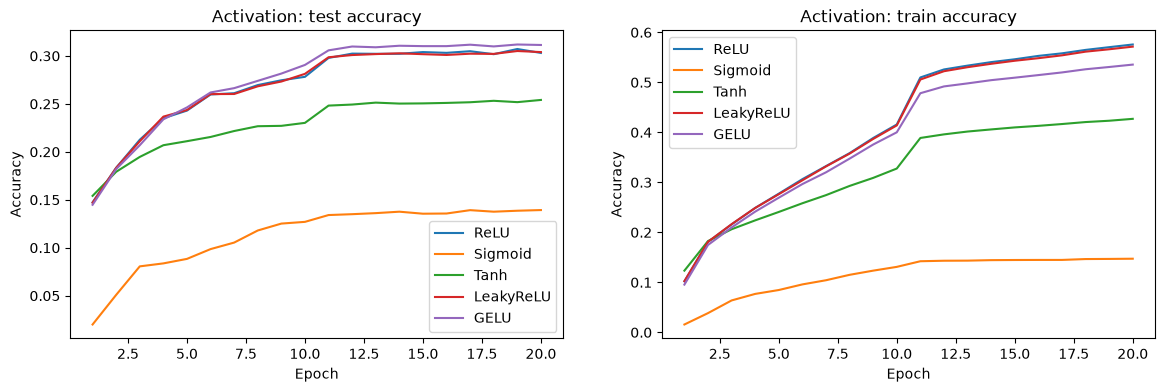

In [43]:
compare("Activation")

**Result:** GELU is best (31.1%), followed by LeakyReLU (30.4%) and ReLU (30.3%).
- **Sigmoid** barely trains (13.9%). Its gradient is at most 0.25 and close to 0 when the input is large, so the weight updates are tiny (vanishing gradients). Its output is also never centred on 0.
- **Tanh** is centred on 0 and does much better (25.4%), but it also saturates for large inputs.
- **ReLU-like** activations (ReLU, LeakyReLU, GELU) don't saturate for positive inputs, so gradients flow well. GELU is a smooth version of ReLU and gives the best test accuracy.

→ **Carry forward: GELU.**

## 15. Sweep 5: Dropout
**Changed:** the dropout rate after each hidden layer. Dropout randomly zeroes this fraction of the neurons during training only; `model.eval()` turns it off for testing.
**Fixed:** 2 × 2048 hidden layers, GELU, no augmentation, SGD + momentum 0.9, lr = 0.005, StepLR.

In [44]:
# "no dropout" is the winning run from Sweep 4, so reuse it
results["Dropout"] = {"no dropout": results["Activation"]["GELU"]}

In [45]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.1).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Dropout", "dropout=0.1", model, optimizer, train_dataloader, scheduler)

Dropout | dropout=0.1 | 10694756 parameters
Epoch  5 | train loss 3.0587, acc 0.2621 | test loss 3.1822, acc 0.2443
Epoch 10 | train loss 2.4634, acc 0.3780 | test loss 2.9839, acc 0.2919
Epoch 15 | train loss 2.1217, acc 0.4631 | test loss 2.9217, acc 0.3091
Epoch 20 | train loss 2.0402, acc 0.4827 | test loss 2.9236, acc 0.3108
Final test accuracy: 0.3108  (76s)


In [46]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Dropout", "dropout=0.2", model, optimizer, train_dataloader, scheduler)

Dropout | dropout=0.2 | 10694756 parameters
Epoch  5 | train loss 3.0982, acc 0.2530 | test loss 3.1891, acc 0.2443
Epoch 10 | train loss 2.5597, acc 0.3560 | test loss 2.9741, acc 0.2921
Epoch 15 | train loss 2.2660, acc 0.4263 | test loss 2.9111, acc 0.3088
Epoch 20 | train loss 2.1911, acc 0.4424 | test loss 2.9063, acc 0.3125
Final test accuracy: 0.3125  (70s)


In [47]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.3).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Dropout", "dropout=0.3", model, optimizer, train_dataloader, scheduler)

Dropout | dropout=0.3 | 10694756 parameters
Epoch  5 | train loss 3.1439, acc 0.2441 | test loss 3.1991, acc 0.2391
Epoch 10 | train loss 2.6604, acc 0.3348 | test loss 2.9722, acc 0.2858
Epoch 15 | train loss 2.3993, acc 0.3966 | test loss 2.9107, acc 0.3063
Epoch 20 | train loss 2.3371, acc 0.4082 | test loss 2.9002, acc 0.3067
Final test accuracy: 0.3067  (72s)


In [48]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.5).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Dropout", "dropout=0.5", model, optimizer, train_dataloader, scheduler)

Dropout | dropout=0.5 | 10694756 parameters
Epoch  5 | train loss 3.2692, acc 0.2191 | test loss 3.2491, acc 0.2302
Epoch 10 | train loss 2.8927, acc 0.2861 | test loss 3.0189, acc 0.2761
Epoch 15 | train loss 2.6791, acc 0.3319 | test loss 2.9543, acc 0.2888
Epoch 20 | train loss 2.6331, acc 0.3413 | test loss 2.9368, acc 0.2936
Final test accuracy: 0.2936  (76s)


no dropout                       final train acc 0.5355 | final test acc 0.3114
dropout=0.1                      final train acc 0.4827 | final test acc 0.3108
dropout=0.2                      final train acc 0.4424 | final test acc 0.3125   <-- best
dropout=0.3                      final train acc 0.4082 | final test acc 0.3067
dropout=0.5                      final train acc 0.3413 | final test acc 0.2936


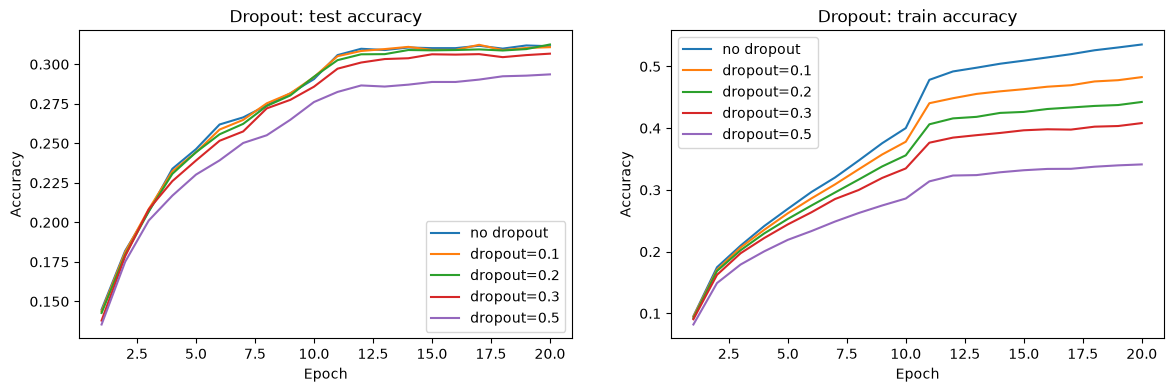

In [49]:
compare("Dropout")

**Result:** dropout = 0.2 is best (31.25%), but only slightly ahead of no dropout (31.14%).
- Dropout clearly reduces overfitting: the gap between train and test accuracy shrinks from 22% (no dropout) to 13% (0.2) and 5% (0.5).
- It also slows learning, though. With only 20 epochs, too much dropout (0.5) leaves the model underfitting, so test accuracy drops.

→ **Carry forward: dropout = 0.2.**

## 16. Sweep 6: Data Augmentation
**Changed:** random transformations applied to the training images (the test images are never augmented). Each epoch sees a slightly different version of every image, which makes memorising the training set harder.
**Fixed:** 2 × 2048 hidden layers, GELU, dropout = 0.2, SGD + momentum 0.9, lr = 0.005, StepLR.

`make_train_dataloader` builds a training loader with the given augmentations, followed by the same `ToTensor` and `Normalize` as before.

In [50]:
def make_train_dataloader(augmentations):
    transform = transforms.Compose(augmentations + [
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    data = datasets.CIFAR100(root="data", train=True, download=True, transform=transform)
    return DataLoader(data, batch_size=batch_size, shuffle=True)

# "no augmentation" is the winning run from Sweep 5, so reuse it
results["Augmentation"] = {"no augmentation": results["Dropout"]["dropout=0.2"]}

In [51]:
aug_dataloader = make_train_dataloader([transforms.RandomHorizontalFlip()])   # mirror left-right with p=0.5

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Augmentation", "horizontal flip", model, optimizer, aug_dataloader, scheduler)

Augmentation | horizontal flip | 10694756 parameters
Epoch  5 | train loss 3.1555, acc 0.2413 | test loss 3.1978, acc 0.2394
Epoch 10 | train loss 2.7333, acc 0.3215 | test loss 2.9487, acc 0.2934
Epoch 15 | train loss 2.5237, acc 0.3671 | test loss 2.8695, acc 0.3117
Epoch 20 | train loss 2.4703, acc 0.3806 | test loss 2.8533, acc 0.3159
Final test accuracy: 0.3159  (80s)


In [52]:
aug_dataloader = make_train_dataloader([transforms.RandomCrop(32, padding=4)])   # shift by up to 4 pixels

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Augmentation", "random crop", model, optimizer, aug_dataloader, scheduler)

Augmentation | random crop | 10694756 parameters
Epoch  5 | train loss 3.4585, acc 0.1803 | test loss 3.4526, acc 0.1834
Epoch 10 | train loss 3.1734, acc 0.2319 | test loss 3.2079, acc 0.2297
Epoch 15 | train loss 3.0342, acc 0.2605 | test loss 3.1436, acc 0.2500
Epoch 20 | train loss 3.0004, acc 0.2640 | test loss 3.1220, acc 0.2553
Final test accuracy: 0.2553  (90s)


In [53]:
aug_dataloader = make_train_dataloader([transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)])

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Augmentation", "color jitter", model, optimizer, aug_dataloader, scheduler)

Augmentation | color jitter | 10694756 parameters
Epoch  5 | train loss 3.1692, acc 0.2415 | test loss 3.2106, acc 0.2412
Epoch 10 | train loss 2.6611, acc 0.3390 | test loss 2.9759, acc 0.2934
Epoch 15 | train loss 2.3889, acc 0.4010 | test loss 2.9265, acc 0.3079
Epoch 20 | train loss 2.3176, acc 0.4172 | test loss 2.9142, acc 0.3127
Final test accuracy: 0.3127  (152s)


In [54]:
aug_dataloader = make_train_dataloader([transforms.RandomRotation(10)])   # rotate by up to ±10 degrees

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Augmentation", "rotation", model, optimizer, aug_dataloader, scheduler)

Augmentation | rotation | 10694756 parameters
Epoch  5 | train loss 3.1647, acc 0.2393 | test loss 3.2399, acc 0.2307
Epoch 10 | train loss 2.7398, acc 0.3173 | test loss 3.0039, acc 0.2807
Epoch 15 | train loss 2.5132, acc 0.3691 | test loss 2.9309, acc 0.2989
Epoch 20 | train loss 2.4632, acc 0.3812 | test loss 2.9157, acc 0.3051
Final test accuracy: 0.3051  (87s)


no augmentation                  final train acc 0.4424 | final test acc 0.3125
horizontal flip                  final train acc 0.3806 | final test acc 0.3159   <-- best
random crop                      final train acc 0.2640 | final test acc 0.2553
color jitter                     final train acc 0.4172 | final test acc 0.3127
rotation                         final train acc 0.3812 | final test acc 0.3051


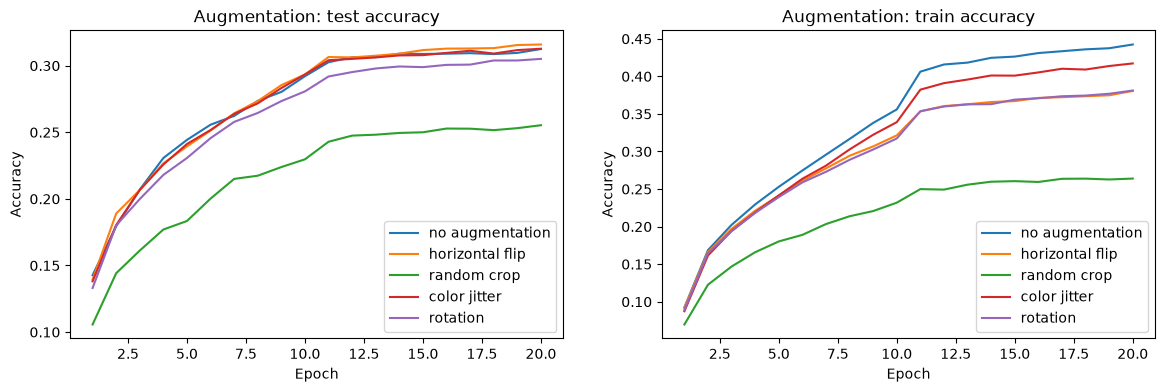

In [55]:
compare("Augmentation")

**Result so far:** horizontal flip is the only augmentation that clearly helps (31.6%). Color jitter is neutral (31.3%).
- **Random crop** hurts a lot (25.5%). An MLP connects every pixel position to its own weights, so it has no idea that an object shifted by 4 pixels is the same object. Shifting every image makes the task much harder for it. A CNN would handle this.
- **Rotation** hurts slightly, for the same reason.
- **Flip** works because its a mirrored image, and the left-right structure of the image is mostly preserved.

One more run: add color jitter on top of the current best (flip), to check whether the two combine well.

In [56]:
aug_dataloader = make_train_dataloader([
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
run_experiment("Augmentation", "flip + color jitter", model, optimizer, aug_dataloader, scheduler)

Augmentation | flip + color jitter | 10694756 parameters
Epoch  5 | train loss 3.2233, acc 0.2292 | test loss 3.2124, acc 0.2369
Epoch 10 | train loss 2.8179, acc 0.3071 | test loss 2.9617, acc 0.2891
Epoch 15 | train loss 2.6185, acc 0.3500 | test loss 2.8917, acc 0.3066
Epoch 20 | train loss 2.5720, acc 0.3589 | test loss 2.8733, acc 0.3130
Final test accuracy: 0.3130  (169s)


no augmentation                  final train acc 0.4424 | final test acc 0.3125
horizontal flip                  final train acc 0.3806 | final test acc 0.3159   <-- best
random crop                      final train acc 0.2640 | final test acc 0.2553
color jitter                     final train acc 0.4172 | final test acc 0.3127
rotation                         final train acc 0.3812 | final test acc 0.3051
flip + color jitter              final train acc 0.3589 | final test acc 0.3130


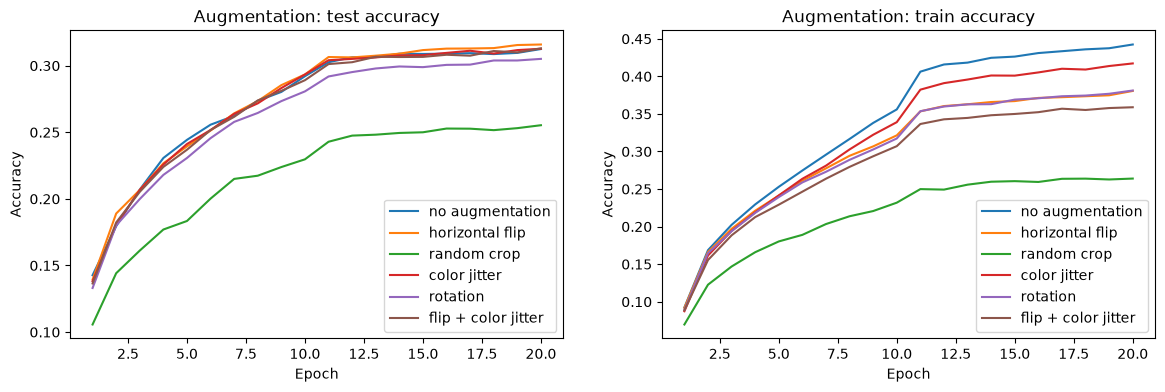

In [57]:
compare("Augmentation")

**Result:** horizontal flip alone stays the best (31.6%). Adding color jitter on top doesn't help (31.3%).

→ **Carry forward: random horizontal flip.**

## 17. Best Model from Experiments 
Best setting from every sweep:

| Setting | Choice |
|---|---|
| Hidden layers | 2 × 2048 |
| Activation | GELU |
| Dropout | 0.2 |
| Data augmentation | random horizontal flip |
| Optimizer | SGD + momentum 0.9 |
| Learning rate | 0.005 |
| Scheduler | StepLR (lr × 0.1 halfway through training) |

With dropout and flipping, the model overfits much less, and test accuracy was still rising at epoch 20. Now that every setting is fixed, the final model trains **twice as long** (40 epochs, with the StepLR drop moved to epoch 20 so the schedule keeps the same shape).

In [58]:
epochs = 40   # the final model trains 2x longer than the sweep runs

final_dataloader = make_train_dataloader([transforms.RandomHorizontalFlip()])

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)
run_experiment("Final", "best settings, 40 epochs", model, optimizer, final_dataloader, scheduler)

Final | best settings, 40 epochs | 10694756 parameters
Epoch  5 | train loss 3.1555, acc 0.2413 | test loss 3.1978, acc 0.2394
Epoch 10 | train loss 2.7333, acc 0.3215 | test loss 2.9487, acc 0.2934
Epoch 15 | train loss 2.4029, acc 0.3868 | test loss 2.8384, acc 0.3153
Epoch 20 | train loss 2.0713, acc 0.4584 | test loss 2.8078, acc 0.3285
Epoch 25 | train loss 1.7886, acc 0.5353 | test loss 2.7509, acc 0.3471
Epoch 30 | train loss 1.7334, acc 0.5467 | test loss 2.7568, acc 0.3516
Epoch 35 | train loss 1.6849, acc 0.5563 | test loss 2.7601, acc 0.3517
Epoch 40 | train loss 1.6476, acc 0.5640 | test loss 2.7608, acc 0.3511
Final test accuracy: 0.3511  (146s)


best settings, 40 epochs         final train acc 0.5640 | final test acc 0.3511   <-- best
best settings, 20 epochs         final train acc 0.3806 | final test acc 0.3159


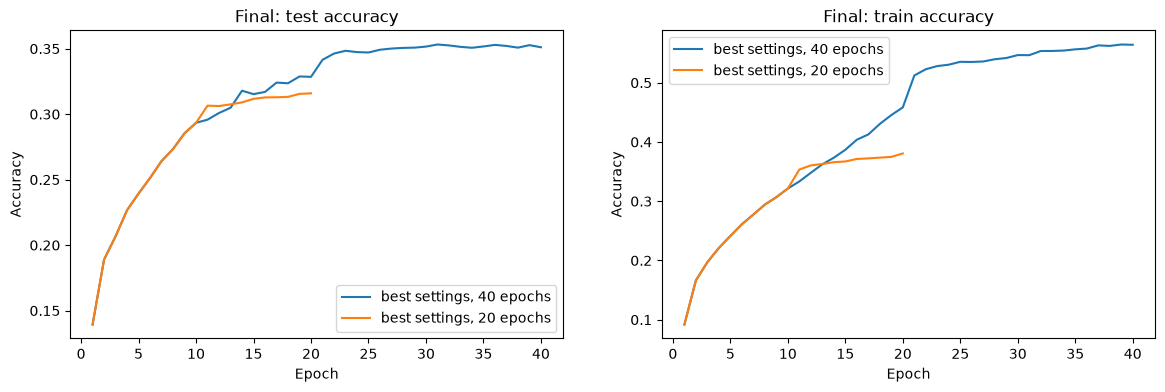

In [59]:
# compare with the same settings trained for 20 epochs (the best run of Sweep 6)
results["Final"]["best settings, 20 epochs"] = results["Augmentation"]["horizontal flip"]
compare("Final")

## 18. Visualize the Results
Predictions of the final model on the first 25 test images (green = correct, red = wrong).

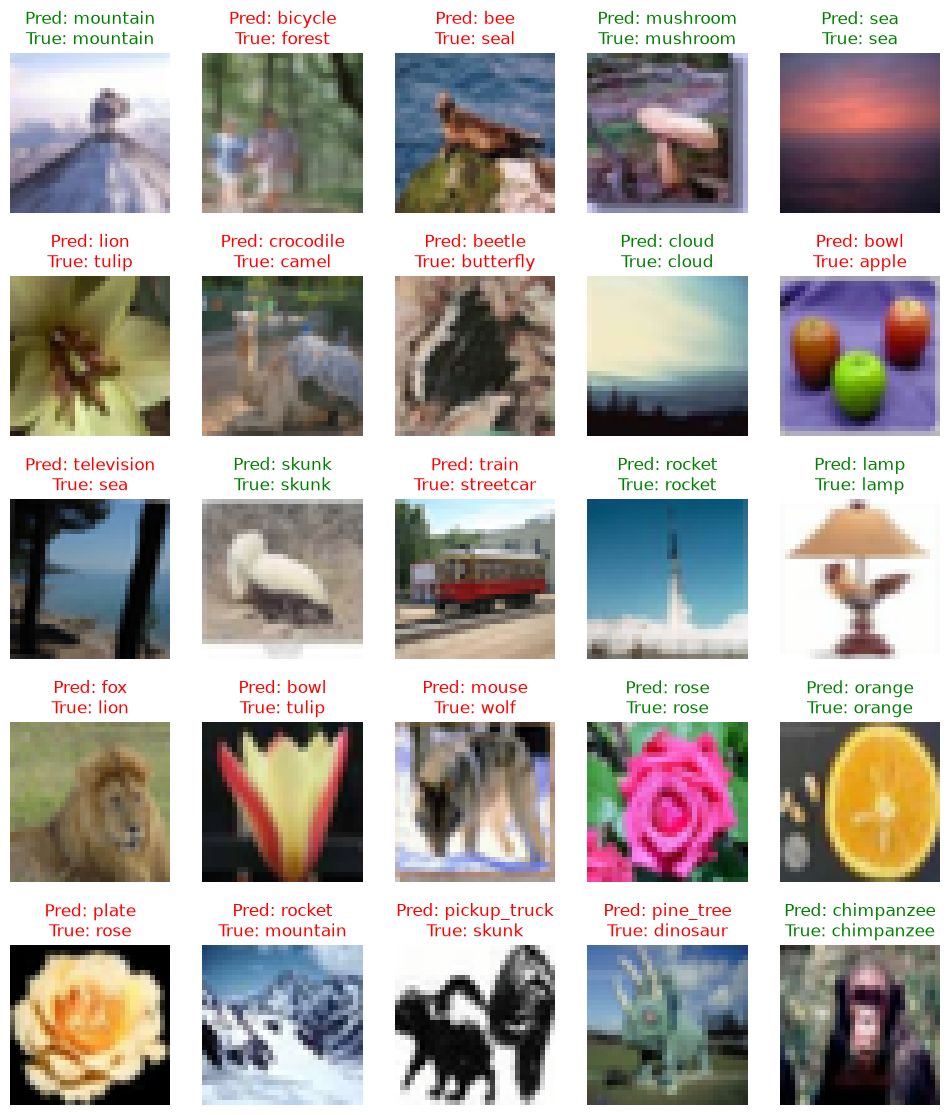

In [60]:
# Test the model for 1 batch
model.eval()
for X, y in test_dataloader:
    X = X.to(device)
    y = y.to(device)
    with torch.no_grad():
        pred = model(X)
        pred_labels = pred.argmax(1)
    break

# Visualize the result
plt.figure(figsize=(12,14))
for i in range(25):
    y_hat = pred_labels[i].item()
    y_gt = y[i].item()
    img = X[i].cpu().permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)   # undo Normalize
    plt.subplot(5,5,i+1)
    plt.imshow(img.clamp(0, 1))
    plt.title("Pred: %s\nTrue: %s" % (classes[y_hat], classes[y_gt]),
              color="green" if y_hat == y_gt else "red")
    plt.axis("off")
plt.show()

## 19. count_parameters
Each layer has (inputs + 1 bias) × outputs parameters:
- Hidden layer 1: (3072 + 1) × 2048 = 6,293,504
- Hidden layer 2: (2048 + 1) × 2048 = 4,196,352
- Output layer: (2048 + 1) × 100 = 204,900
- **Total: 10,694,756.** GELU, Dropout and Flatten have no parameters.

In [61]:
print(model)
print("Trainable parameters:", count_parameters(model))

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=2048, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=2048, out_features=2048, bias=True)
    (4): GELU(approximate='none')
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=2048, out_features=100, bias=True)
  )
)
Trainable parameters: 10694756


## 20. Summary of all Sweeps

Sweep          Best run                     Final test acc
Baseline       SGD, lr=0.01                 0.2362
Optimizer      SGD+momentum, lr=0.01        0.2550
Learning rate  lr=0.005                     0.2690
Scheduler      StepLR                       0.2892
Depth          2 x 512                      0.2892
Width          2 x 2048                     0.3031
Activation     GELU                         0.3114
Dropout        dropout=0.2                  0.3125
Augmentation   horizontal flip              0.3159
Final          best settings, 40 epochs     0.3511


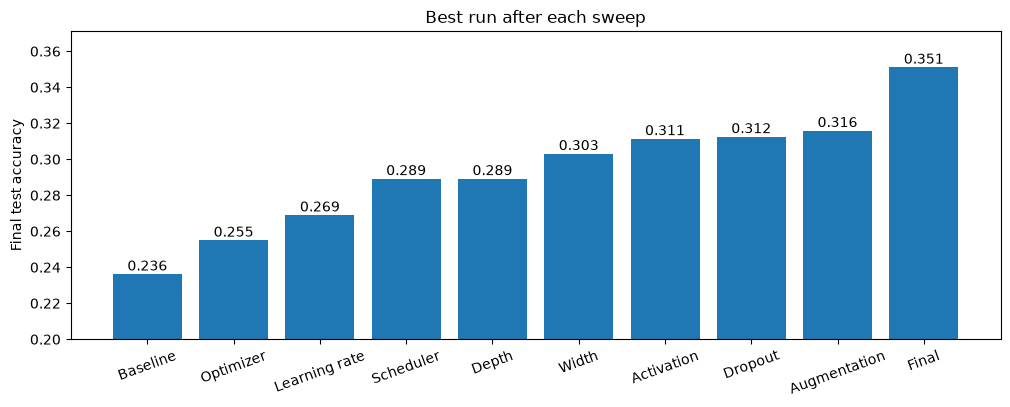

In [63]:
names = []
accs = []
print("%-14s %-28s %s" % ("Sweep", "Best run", "Final test acc"))
for sweep, runs in results.items():
    best = max(runs, key=lambda label: runs[label]["test_acc"][-1])
    acc = runs[best]["test_acc"][-1]
    print("%-14s %-28s %.4f" % (sweep, best, acc))
    names.append(sweep)
    accs.append(acc)

plt.figure(figsize=(12,4))
plt.bar(names, accs)
for i, acc in enumerate(accs):
    plt.text(i, acc + 0.002, "%.3f" % acc, ha="center")
plt.ylim(0.2, max(accs) + 0.02)
plt.xticks(rotation=20)
plt.ylabel("Final test accuracy")
plt.title("Best run after each sweep")
plt.show()

## 21. Checkpoint
- Test accuracy went from **23.6%** (baseline) to **35.1%** (final model). A random guess would get 1%.
- **Optimization settings gave the biggest gains:** momentum (+1.9%), a smaller learning rate (+1.4%), StepLR (+2.0%), and training the final model longer (+3.5%). After those came wider layers (+1.4%) and GELU (+0.8%).
- **Overfitting is the main problem** Without regularization, train accuracy passes 70% while test accuracy stalls around 25%. Dropout, horizontal flipping and lowering the lr all reduce the gap. That is why the final model could train for 40 epochs without its test accuracy dropping.
- **Augmentations that move pixels (crop, rotation) hurt**, because an MLP learns separate weights for every pixel position.


## 22. Longer Training Run (120 epochs)
**Changed:** the number of epochs, 120 instead of 40.
**Fixed:** everything else in the final model (2 × 2048 hidden layers, GELU, dropout = 0.2, horizontal flip, SGD + momentum 0.9, lr = 0.005).

The StepLR drop stays halfway through training (now at epoch 60), the same shape as in the 20- and 40-epoch runs.

In [ ]:
epochs = 120   # 3x longer than the final model

torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=60, gamma=0.1)
run_experiment("Longer training", "120 epochs", model, optimizer, final_dataloader, scheduler)

Longer training | 120 epochs | 10694756 parameters
Epoch  5 | train loss 3.1555, acc 0.2413 | test loss 3.1978, acc 0.2394
Epoch 10 | train loss 2.7333, acc 0.3215 | test loss 2.9487, acc 0.2934
Epoch 15 | train loss 2.4029, acc 0.3868 | test loss 2.8384, acc 0.3153
Epoch 20 | train loss 2.0713, acc 0.4584 | test loss 2.8078, acc 0.3285
Epoch 25 | train loss 1.7401, acc 0.5353 | test loss 2.8454, acc 0.3342
Epoch 30 | train loss 1.4100, acc 0.6149 | test loss 2.9184, acc 0.3367
Epoch 35 | train loss 1.1107, acc 0.6930 | test loss 3.0483, acc 0.3376
Epoch 40 | train loss 0.8558, acc 0.7596 | test loss 3.2059, acc 0.3392
Epoch 45 | train loss 0.6490, acc 0.8179 | test loss 3.3261, acc 0.3409
Epoch 50 | train loss 0.4995, acc 0.8595 | test loss 3.4709, acc 0.3379
Epoch 55 | train loss 0.3833, acc 0.8955 | test loss 3.6461, acc 0.3353
Epoch 60 | train loss 0.3003, acc 0.9201 | test loss 3.7364, acc 0.3381
Epoch 65 | train loss 0.1849, acc 0.9578 | test loss 3.7239, acc 0.3477
Epoch 70 | tr

120 epochs                       final train acc 0.9755 | final test acc 0.3502
40 epochs                        final train acc 0.5640 | final test acc 0.3511   <-- best


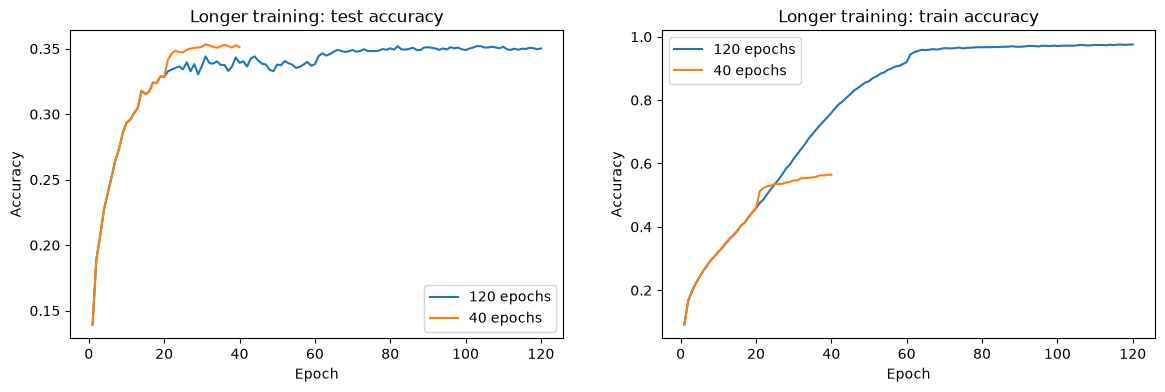

In [10]:
# compare with the 40-epoch final model from section 17
results["Longer training"]["40 epochs"] = results["Final"]["best settings, 40 epochs"]
compare("Longer training")

**Result:** training 3× longer does not help: 35.0% after 120 epochs vs 35.1% after 40 epochs.
- During the 60 epochs at lr = 0.005 the model memorises the training set: train accuracy reaches 92% at epoch 60 and 97.6% at the end. Test accuracy stays at 33–34% over that time, and test loss rises from 2.81 (epoch 20) to 3.74 (epoch 60).
- The lr drop at epoch 60 gives the usual jump of about 1%, but that only brings test accuracy back to the level the 40-epoch run already reached.
- Dropout = 0.2 and flipping are not enough regularization for a run this long. More epochs alone don't push this MLP further.

→ **The 40-epoch model from section 17 stays the final model.**

## 23. Stronger Dropout (120 epochs)
The 120-epoch run in section 22 memorised the training set (97.6% train accuracy), so dropout = 0.2 is too weak for a run this long.

**Changed:** the dropout rate.
**Fixed:** everything else from section 22 (2 × 2048 hidden layers, GELU, horizontal flip, SGD + momentum 0.9, lr = 0.005, StepLR drop at epoch 60, 120 epochs).

In [11]:
epochs = 120   # same as section 22

# dropout=0.2 is the 120-epoch run from section 22, so reuse it
results["Dropout (120 epochs)"] = {"dropout=0.2": results["Longer training"]["120 epochs"]}

In [12]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.3).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=60, gamma=0.1)
run_experiment("Dropout (120 epochs)", "dropout=0.3", model, optimizer, final_dataloader, scheduler)

Dropout (120 epochs) | dropout=0.3 | 10694756 parameters
Epoch  5 | train loss 3.1938, acc 0.2350 | test loss 3.2108, acc 0.2393
Epoch 10 | train loss 2.8080, acc 0.3038 | test loss 2.9629, acc 0.2903
Epoch 15 | train loss 2.5156, acc 0.3611 | test loss 2.8450, acc 0.3140
Epoch 20 | train loss 2.2451, acc 0.4203 | test loss 2.7813, acc 0.3276
Epoch 25 | train loss 1.9793, acc 0.4784 | test loss 2.7757, acc 0.3360
Epoch 30 | train loss 1.7168, acc 0.5346 | test loss 2.7938, acc 0.3415
Epoch 35 | train loss 1.4675, acc 0.5958 | test loss 2.8522, acc 0.3374
Epoch 40 | train loss 1.2428, acc 0.6512 | test loss 2.9442, acc 0.3447
Epoch 45 | train loss 1.0328, acc 0.7052 | test loss 3.0043, acc 0.3440
Epoch 50 | train loss 0.8499, acc 0.7571 | test loss 3.1207, acc 0.3423
Epoch 55 | train loss 0.7157, acc 0.7914 | test loss 3.2098, acc 0.3424
Epoch 60 | train loss 0.5984, acc 0.8264 | test loss 3.3065, acc 0.3420
Epoch 65 | train loss 0.4081, acc 0.8886 | test loss 3.3084, acc 0.3516
Epoch 7

In [13]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.5).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=60, gamma=0.1)
run_experiment("Dropout (120 epochs)", "dropout=0.5", model, optimizer, final_dataloader, scheduler)

Dropout (120 epochs) | dropout=0.5 | 10694756 parameters
Epoch  5 | train loss 3.3074, acc 0.2096 | test loss 3.2574, acc 0.2260
Epoch 10 | train loss 2.9935, acc 0.2670 | test loss 3.0268, acc 0.2744
Epoch 15 | train loss 2.7787, acc 0.3079 | test loss 2.9142, acc 0.2971
Epoch 20 | train loss 2.6036, acc 0.3418 | test loss 2.8349, acc 0.3120
Epoch 25 | train loss 2.4400, acc 0.3741 | test loss 2.7793, acc 0.3227
Epoch 30 | train loss 2.2970, acc 0.4035 | test loss 2.7518, acc 0.3350
Epoch 35 | train loss 2.1535, acc 0.4334 | test loss 2.7320, acc 0.3412
Epoch 40 | train loss 2.0166, acc 0.4622 | test loss 2.7308, acc 0.3378
Epoch 45 | train loss 1.8832, acc 0.4906 | test loss 2.7254, acc 0.3456
Epoch 50 | train loss 1.7747, acc 0.5159 | test loss 2.7375, acc 0.3428
Epoch 55 | train loss 1.6652, acc 0.5409 | test loss 2.7614, acc 0.3482
Epoch 60 | train loss 1.5584, acc 0.5661 | test loss 2.7738, acc 0.3416
Epoch 65 | train loss 1.2928, acc 0.6358 | test loss 2.7436, acc 0.3573
Epoch 7

In [14]:
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.7).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=60, gamma=0.1)
run_experiment("Dropout (120 epochs)", "dropout=0.7", model, optimizer, final_dataloader, scheduler)

Dropout (120 epochs) | dropout=0.7 | 10694756 parameters
Epoch  5 | train loss 3.5210, acc 0.1694 | test loss 3.4019, acc 0.2047
Epoch 10 | train loss 3.2949, acc 0.2053 | test loss 3.2536, acc 0.2345
Epoch 15 | train loss 3.1736, acc 0.2282 | test loss 3.1664, acc 0.2506
Epoch 20 | train loss 3.0874, acc 0.2434 | test loss 3.1223, acc 0.2630
Epoch 25 | train loss 3.0187, acc 0.2578 | test loss 3.0922, acc 0.2667
Epoch 30 | train loss 2.9568, acc 0.2686 | test loss 3.0153, acc 0.2847
Epoch 35 | train loss 2.9094, acc 0.2777 | test loss 3.0203, acc 0.2818
Epoch 40 | train loss 2.8688, acc 0.2842 | test loss 2.9897, acc 0.2861
Epoch 45 | train loss 2.8281, acc 0.2924 | test loss 2.9938, acc 0.2900
Epoch 50 | train loss 2.7904, acc 0.2991 | test loss 2.9606, acc 0.2946
Epoch 55 | train loss 2.7590, acc 0.3064 | test loss 2.9385, acc 0.2973
Epoch 60 | train loss 2.7261, acc 0.3081 | test loss 2.9508, acc 0.2998
Epoch 65 | train loss 2.4932, acc 0.3586 | test loss 2.8103, acc 0.3235
Epoch 7

dropout=0.2                      final train acc 0.9755 | final test acc 0.3502
dropout=0.3                      final train acc 0.9258 | final test acc 0.3536
dropout=0.5                      final train acc 0.7041 | final test acc 0.3612   <-- best
dropout=0.7                      final train acc 0.4092 | final test acc 0.3379


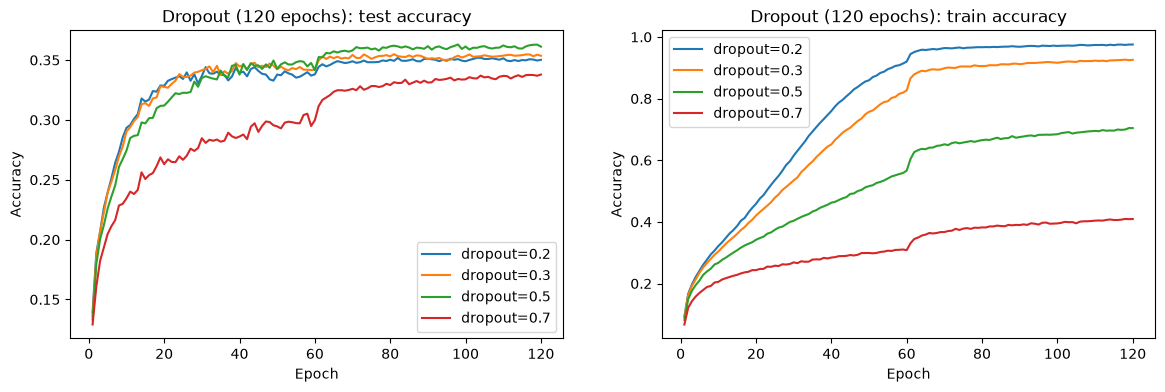

In [15]:
compare("Dropout (120 epochs)")

**Result:** dropout = 0.5 is best (36.1%). It beats the 40-epoch final model from section 17 (35.1%) and is the best model in this notebook.
- Stronger dropout slows memorisation: final train accuracy falls from 97.6% (0.2) to 92.6% (0.3), 70.4% (0.5) and 40.9% (0.7).
- With dropout = 0.5 the test loss stays flat at about 2.75 instead of rising to 3.85 (0.2), so the longer run now pays off.
- Dropout = 0.7 is too strong: the model underfits and ends at 33.8%, although its test accuracy is still rising slowly at epoch 120.
- This reverses the 20-epoch sweep in section 15, where 0.5 was the worst setting. The best dropout rate depends on how long the model trains.

→ **Best model: dropout = 0.5 trained for 120 epochs (36.1%). However still far from 45% Target**

## 24. Reaching 45%: Input Whitening
Sections 22–23 topped out at 36%, far from the 45% target.
- **24a** shows the search for something better, made with a separate script outside this notebook. Mixup, label smoothing, weight decay and wider or deeper layers all stayed below 40%, until one run with **whitened input** reached 47.5%.
- **24b** explains whitening and builds it into the model.

### 24a. The Search Outside the Notebook
After section 23 the best model was at 36.1% and the target was 45%. To try many ideas quickly, the runs in this part were made with a separate script, not with the notebook cells:
- The script builds the same kind of model (Flatten, Linear, activation, Dropout) and trains it with SGD + momentum 0.9, batch size 128 and a cosine learning rate schedule, unless a run says otherwise.
- It keeps all images on the GPU, so one epoch takes about 1 second and several runs can train at the same time.
- Every run reports its test accuracy after the last epoch, as in the rest of the notebook.

**The cells below do not train anything.** They hold the results copied from the script's logs and plot them. The script (`explore.py`) and the log of every run are in the `search/`

In the run descriptions, "crop 4" means a random crop with 4 pixels of padding (the image is shifted by up to 4 pixels). Every run also uses the horizontal flip.

In [1]:
from matplotlib.patches import Patch

def show_search(title, plain_runs, whitened_runs):
    # each run is (description, final test accuracy), copied from the search logs
    runs = sorted([(acc, text, "silver") for text, acc in plain_runs] +
                  [(acc, text, "tab:blue") for text, acc in whitened_runs])
    for acc, text, color in reversed(runs):
        print("%.4f  %s" % (acc, text))

    plt.figure(figsize=(10, 0.3*len(runs) + 1.5))
    plt.barh([text for acc, text, color in runs], [acc for acc, text, color in runs],
             color=[color for acc, text, color in runs])
    target = plt.axvline(0.45, color="black", linestyle="--", linewidth=1, label="target 45%")
    handles = [target]
    for group, name in [("silver", "without whitening"), ("tab:blue", "with whitening")]:
        best = [(acc, i) for i, (acc, text, color) in enumerate(runs) if color == group]
        if best:
            acc, i = max(best)
            plt.text(acc + 0.005, i, "%.1f%%" % (100*acc), va="center")   # label the best run of this colour
            handles.append(Patch(color=group, label=name))
    plt.legend(handles=handles, loc="lower right")
    plt.gca().spines[["top", "right"]].set_visible(False)
    plt.xlim(0, 0.6)
    plt.xlabel("Final test accuracy")
    plt.title(title)
    plt.show()

**Round 1 (12 runs, 300 epochs each).** The section 23 model trained longer, with combinations of random crop, dropout, mixup, label smoothing, weight decay and wider or deeper layers.
Unless the description says otherwise: 2 × 2048 hidden layers, GELU, lr = 0.005, no weight decay.

0.3794  crop 4, dropout 0.2, lr 0.02, weight decay 5e-4
0.3772  crop 2, dropout 0.3
0.3680  dropout 0.5, mixup 0.4, label smoothing 0.1
0.3659  crop 4, dropout 0.2, mixup 0.2
0.3654  dropout 0.5 (the section 23 model)
0.3617  crop 4, dropout 0.3, 2 x 4096
0.3594  dropout 0.5, lr 0.02, weight decay 5e-4
0.3502  crop 4, dropout 0.3, 3 x 4096
0.3495  crop 4, dropout 0.2, label smoothing 0.1
0.3468  crop 4, dropout 0.2
0.3431  crop 4, dropout 0.5
0.2768  crop 4, dropout 0.2, lr 0.02 (no weight decay)


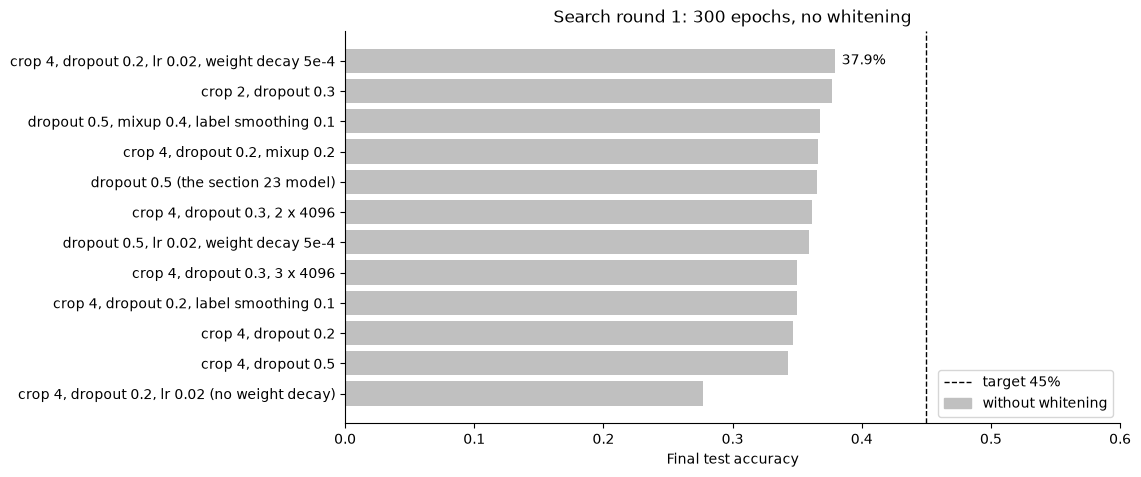

In [2]:
round1 = [
    ("dropout 0.5 (the section 23 model)", 0.3654),
    ("dropout 0.5, lr 0.02, weight decay 5e-4", 0.3594),
    ("dropout 0.5, mixup 0.4, label smoothing 0.1", 0.3680),
    ("crop 4, dropout 0.5", 0.3431),
    ("crop 4, dropout 0.2", 0.3468),
    ("crop 4, dropout 0.2, label smoothing 0.1", 0.3495),
    ("crop 4, dropout 0.2, mixup 0.2", 0.3659),
    ("crop 4, dropout 0.2, lr 0.02 (no weight decay)", 0.2768),
    ("crop 4, dropout 0.2, lr 0.02, weight decay 5e-4", 0.3794),
    ("crop 2, dropout 0.3", 0.3772),
    ("crop 4, dropout 0.3, 2 x 4096", 0.3617),
    ("crop 4, dropout 0.3, 3 x 4096", 0.3502),
]
show_search("Search round 1: 300 epochs, no whitening", round1, [])

**Result of round 1:** nothing gets close to 45%. The best run reaches 37.9% (random crop with lr = 0.02 and weight decay). The same run without weight decay drops to 27.7%. Averaging the predictions of the 5 best runs (an ensemble) gives 42.0%, still short of the target.

**Round 2 (24 runs, 200 epochs each).** The base is the best run of round 1: crop 4, dropout = 0.2, lr = 0.02, weight decay = 5e-4. Every other run changes one thing in the base (one run changes two).

0.4747  input whitening (ZCA)
0.3917  crop 2 and weight decay 1e-3
0.3878  16 x 16 input (2 x 2 average pooling)
0.3871  mixup 1.0
0.3829  crop 2 instead of crop 4
0.3808  2 x 4096
0.3803  mixup 0.2
0.3764  weight decay 1e-3
0.3737  label smoothing 0.1
0.3725  SAM optimizer, rho 0.05
0.3699  dropout 0.2 on the input too
0.3677  averaged weights (EMA)
0.3674  lr 0.01
0.3673  base (best of round 1)
0.3667  SAM optimizer, rho 0.2
0.3664  512-unit linear layer before the hidden layers
0.3632  dropout 0.4
0.3614  batch size 64
0.3595  lr 0.05
0.3566  no dropout
0.3564  weight decay 2e-3
0.3488  3 x 2048
0.3367  1 x 8192
0.2413  AdamW, lr 0.001, weight decay 0.05


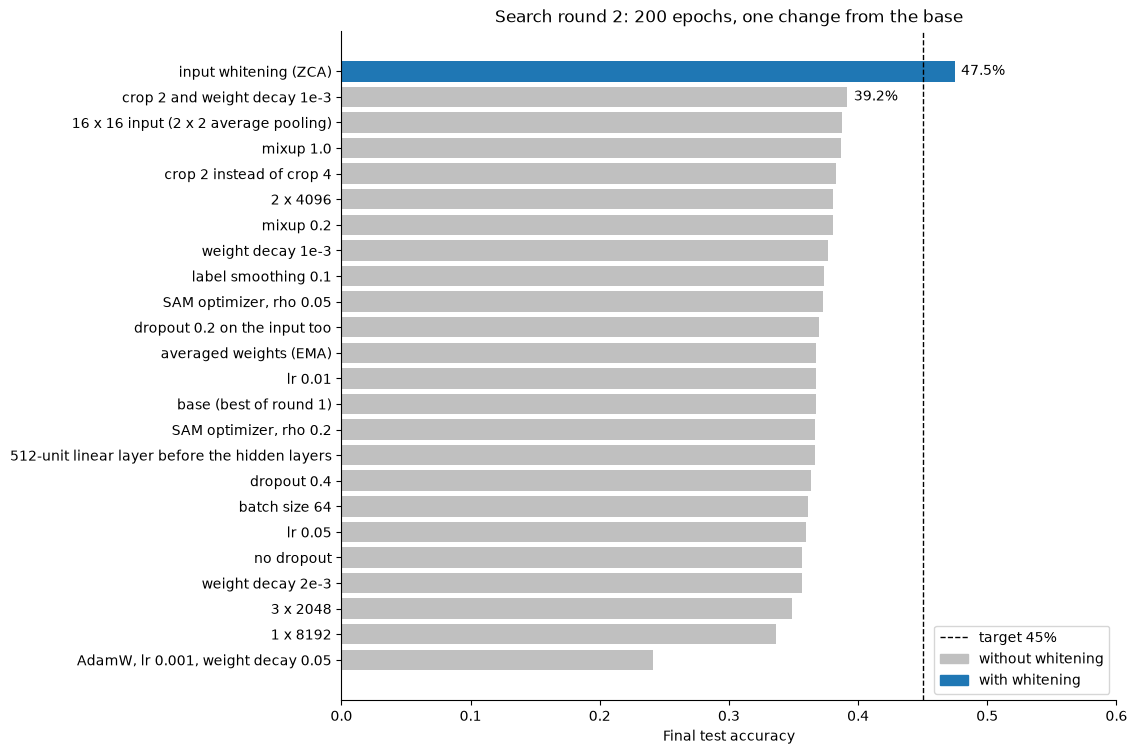

In [3]:
round2 = [
    ("base (best of round 1)", 0.3673),
    ("crop 2 instead of crop 4", 0.3829),
    ("crop 2 and weight decay 1e-3", 0.3917),
    ("weight decay 1e-3", 0.3764),
    ("weight decay 2e-3", 0.3564),
    ("lr 0.05", 0.3595),
    ("lr 0.01", 0.3674),
    ("mixup 0.2", 0.3803),
    ("mixup 1.0", 0.3871),
    ("label smoothing 0.1", 0.3737),
    ("SAM optimizer, rho 0.05", 0.3725),
    ("SAM optimizer, rho 0.2", 0.3667),
    ("AdamW, lr 0.001, weight decay 0.05", 0.2413),
    ("batch size 64", 0.3614),
    ("averaged weights (EMA)", 0.3677),
    ("no dropout", 0.3566),
    ("dropout 0.4", 0.3632),
    ("dropout 0.2 on the input too", 0.3699),
    ("2 x 4096", 0.3808),
    ("3 x 2048", 0.3488),
    ("1 x 8192", 0.3367),
    ("512-unit linear layer before the hidden layers", 0.3664),
    ("16 x 16 input (2 x 2 average pooling)", 0.3878),
]
round2_whitened = [
    ("input whitening (ZCA)", 0.4747),
]
show_search("Search round 2: 200 epochs, one change from the base", round2, round2_whitened)

**Result of round 2:** 23 of the 24 runs end between 24.1% and 39.2%. The one exception is **input whitening at 47.5%**. It is the only change that passes 45%, and it is 10.7% above the same run without whitening (36.7%).

The next cell shows the log of that first whitening run next to the base run. Whitening is slightly behind at epoch 10, ahead at every check from epoch 20 on, and passes 45% at epoch 130.

        without whitening     with whitening
epoch   train acc  test acc   train acc  test acc
   10   0.2426     0.2180     0.1979     0.2031
   20   0.2854     0.2500     0.2654     0.2781
   30   0.3132     0.2435     0.3135     0.3180
   40   0.3340     0.2534     0.3516     0.3450
   50   0.3607     0.2602     0.3836     0.3662
   60   0.3856     0.2671     0.4103     0.3837
   70   0.4136     0.2772     0.4345     0.4051
   80   0.4433     0.2901     0.4582     0.4142
   90   0.4720     0.2978     0.4809     0.4218
  100   0.5079     0.3095     0.5034     0.4328
  110   0.5451     0.3099     0.5232     0.4383
  120   0.5758     0.3296     0.5427     0.4473
  130   0.6135     0.3376     0.5592     0.4542
  140   0.6445     0.3472     0.5730     0.4597
  150   0.6718     0.3549     0.5854     0.4636
  160   0.6997     0.3586     0.5980     0.4674
  170   0.7173     0.3614     0.6084     0.4699
  180   0.7271     0.3670     0.6094     0.4733
  190   0.7348     0.3677     0.6153     

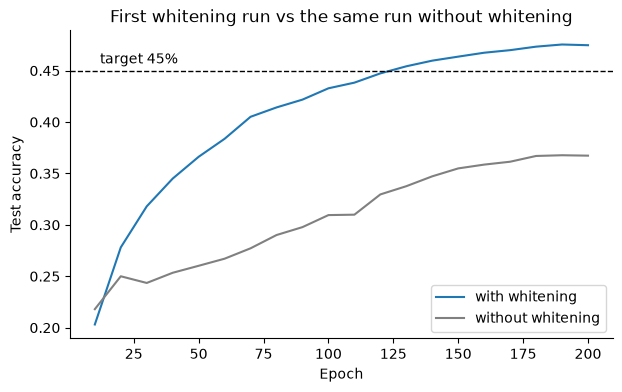

In [4]:
# train and test accuracy every 10 epochs, copied from the logs of the two runs
search_epochs = list(range(10, 201, 10))
base_train = [0.2426, 0.2854, 0.3132, 0.3340, 0.3607, 0.3856, 0.4136, 0.4433, 0.4720, 0.5079, 0.5451, 0.5758, 0.6135, 0.6445, 0.6718, 0.6997, 0.7173, 0.7271, 0.7348, 0.7392]
base_test = [0.2180, 0.2500, 0.2435, 0.2534, 0.2602, 0.2671, 0.2772, 0.2901, 0.2978, 0.3095, 0.3099, 0.3296, 0.3376, 0.3472, 0.3549, 0.3586, 0.3614, 0.3670, 0.3677, 0.3673]
white_train = [0.1979, 0.2654, 0.3135, 0.3516, 0.3836, 0.4103, 0.4345, 0.4582, 0.4809, 0.5034, 0.5232, 0.5427, 0.5592, 0.5730, 0.5854, 0.5980, 0.6084, 0.6094, 0.6153, 0.6160]
white_test = [0.2031, 0.2781, 0.3180, 0.3450, 0.3662, 0.3837, 0.4051, 0.4142, 0.4218, 0.4328, 0.4383, 0.4473, 0.4542, 0.4597, 0.4636, 0.4674, 0.4699, 0.4733, 0.4754, 0.4747]

print("        without whitening     with whitening")
print("epoch   train acc  test acc   train acc  test acc")
for i in range(len(search_epochs)):
    print("%5d   %.4f     %.4f     %.4f     %.4f"
          % (search_epochs[i], base_train[i], base_test[i], white_train[i], white_test[i]))

plt.figure(figsize=(7,4))
plt.plot(search_epochs, white_test, color="tab:blue", label="with whitening")
plt.plot(search_epochs, base_test, color="gray", label="without whitening")
plt.axhline(0.45, color="black", linestyle="--", linewidth=1)   # the 45% target
plt.text(12, 0.457, "target 45%")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.title("First whitening run vs the same run without whitening")
plt.xlabel("Epoch")
plt.ylabel("Test accuracy")
plt.legend(loc="lower right")
plt.show()

**Round 3 (21 runs).** Every run uses whitening. The base is the whitening run from round 2 (crop 4, dropout = 0.2, lr = 0.02, weight decay = 5e-4, 200 epochs), and every other run changes one thing in it. The last run in the list puts whitening on the section 23 model without changing anything else.

0.4970  400 epochs
0.4853  lr 0.05
0.4766  ReLU instead of GELU
0.4747  base (the round 2 whitening run)
0.4740  StepLR instead of cosine
0.4728  weight decay 2e-4
0.4700  whitening eps 0.03
0.4678  whitening eps 0.01
0.4675  crop 2 instead of crop 4
0.4656  whitening eps 0.3
0.4655  2 x 4096
0.4634  no dropout
0.4547  label smoothing 0.1
0.4508  dropout 0.4
0.4450  mixup 0.2
0.4429  whitening eps 1.0
0.4404  3 x 2048
0.4309  lr 0.01
0.4216  weight decay 1e-3
0.3723  mixup 1.0
0.2876  no random crop (flip only)
0.2806  section 23 model + whitening (flip only, lr 0.005, 120 epochs)


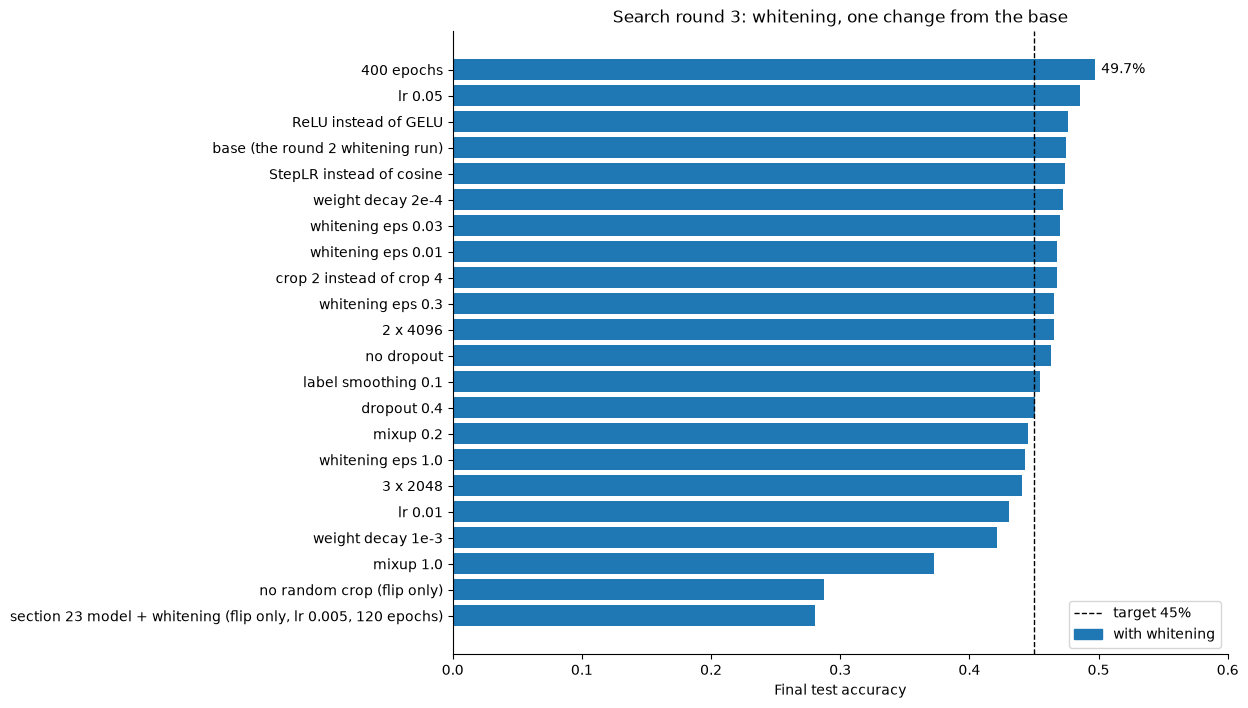

In [5]:
round3_whitened = [
    ("base (the round 2 whitening run)", 0.4747),
    ("lr 0.05", 0.4853),
    ("lr 0.01", 0.4309),
    ("weight decay 2e-4", 0.4728),
    ("weight decay 1e-3", 0.4216),
    ("whitening eps 0.01", 0.4678),
    ("whitening eps 0.03", 0.4700),
    ("whitening eps 0.3", 0.4656),
    ("whitening eps 1.0", 0.4429),
    ("crop 2 instead of crop 4", 0.4675),
    ("no random crop (flip only)", 0.2876),
    ("mixup 0.2", 0.4450),
    ("mixup 1.0", 0.3723),
    ("label smoothing 0.1", 0.4547),
    ("no dropout", 0.4634),
    ("dropout 0.4", 0.4508),
    ("2 x 4096", 0.4655),
    ("3 x 2048", 0.4404),
    ("ReLU instead of GELU", 0.4766),
    ("StepLR instead of cosine", 0.4740),
    ("400 epochs", 0.4970),
    ("section 23 model + whitening (flip only, lr 0.005, 120 epochs)", 0.2806),
]
show_search("Search round 3: whitening, one change from the base", [], round3_whitened)

**Result of round 3:** whitening is not enough on its own.
- **It needs random crop.** Without it the run falls to 28.8%. The section 23 model with whitening added (no crop, lr = 0.005) ends at 28.1%, worse than the 36.1% it had without whitening.
- **It wants a higher learning rate.** lr = 0.05 is the best 200-epoch run (48.5%), and lr = 0.01 loses 4.4%.
- **Mixup and more weight decay now hurt**, and the whitening strength (eps) hardly matters between 0.01 and 0.3.
- Training for 400 epochs reaches 49.7%.

A last round of 16 runs tuned the settings around lr = 0.05. At 200 epochs, dropout 0.1 / 0.2 / 0.3 gave 48.8% / 48.5% / 47.0%, weight decay 2e-4 / 5e-4 / 1e-3 gave 47.4% / 48.5% / 42.5%, lr = 0.1 gave 46.0%, and a second random seed gave 48.4%. Dropout 0.1 is 0.3% above 0.2, which is too small a difference to trust from one run each, so the recipe keeps 0.2.

→ **Recipe for section 25: whitening, random crop + flip, dropout = 0.2, lr = 0.05, weight decay = 5e-4, cosine schedule, 200 epochs.**

### 24b. Whitening the Input
**What whitening does.** Neighbouring pixels in a photo are almost identical, so most of the 3072 inputs repeat the same information (overall brightness and colour). The details (edges, textures) are tiny by comparison. ZCA whitening multiplies the image by a fixed 3072 × 3072 matrix that removes these correlations. The result still looks like the image, but edges and textures are boosted.

**How it is implemented.** The matrix is computed once from the training images only; the test images are not used. It is then loaded into a **fixed `nn.Linear` layer** in front of the MLP. That layer is never trained (`requires_grad_(False)`), so it is preprocessing, like `Normalize`. The model still uses only Flatten, Linear, activation and Dropout layers.

In [11]:
# all 50,000 normalized training images as one [50000, 3072] matrix
train_images = torch.stack([img for img, _ in training_data]).flatten(1).to(device)

zca_mean = train_images.mean(0)                          # mean of each of the 3072 inputs
centered = train_images - zca_mean
cov = (centered.T @ centered / len(centered)).double()   # 3072 x 3072 covariance matrix
eigvals, eigvecs = torch.linalg.eigh(cov)                # its eigenvalues and eigenvectors
zca_eps = 0.1                                            # stops tiny, noisy directions from being blown up
zca_matrix = (eigvecs @ torch.diag(1 / torch.sqrt(eigvals + zca_eps)) @ eigvecs.T).float()
print("Whitening matrix:", zca_matrix.shape)

Whitening matrix: torch.Size([3072, 3072])


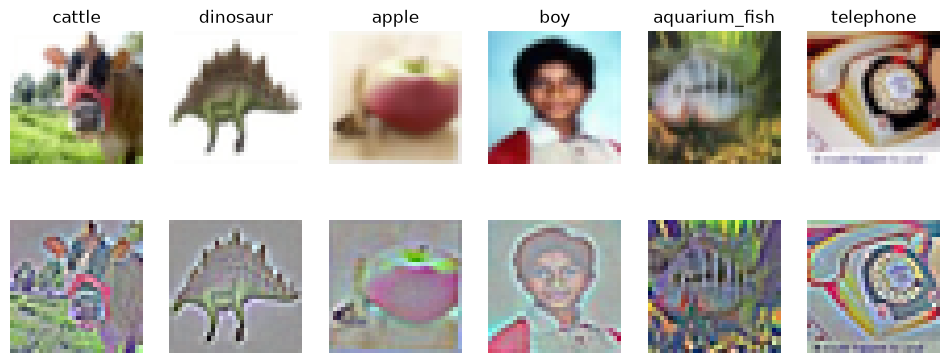

In [12]:
# first 6 training images: original (top) and whitened (bottom)
plt.figure(figsize=(12,4.5))
for i in range(6):
    img, label = training_data[i]
    white = (zca_matrix @ (img.flatten().to(device) - zca_mean)).view(3, 32, 32).cpu()
    white = (white - white.min()) / (white.max() - white.min())   # rescale to 0..1 for display

    plt.subplot(2,6,i+1)
    plt.imshow((img.permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)).clamp(0, 1))
    plt.title(classes[label])
    plt.axis("off")
    plt.subplot(2,6,i+7)
    plt.imshow(white.permute(1, 2, 0))
    plt.axis("off")
plt.show()

In [13]:
class WhitenedMLP(MLP):
    # the same MLP with a fixed whitening layer in front
    def __init__(self, hidden_sizes, activation, dropout):
        super(WhitenedMLP, self).__init__(hidden_sizes, activation, dropout)
        self.whiten = nn.Linear(32*32*3, 32*32*3)
        self.whiten.weight.data = zca_matrix               # computes zca_matrix @ (x - zca_mean)
        self.whiten.bias.data = -zca_matrix @ zca_mean
        self.whiten.requires_grad_(False)                  # fixed preprocessing, never trained

    # define data passing flow
    def forward(self, x):
        x = self.flatten(x)
        x = self.whiten(x)
        logits = self.layers(x)
        return logits

model = WhitenedMLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2)
print(model)
print("Trainable parameters:", count_parameters(model))

WhitenedMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=2048, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=2048, out_features=2048, bias=True)
    (4): GELU(approximate='none')
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=2048, out_features=100, bias=True)
  )
  (whiten): Linear(in_features=3072, out_features=3072, bias=True)
)
Trainable parameters: 10694756


## 25. Whitening + Random Crop + Higher Learning Rate with Weight Decay
Whitening changes how the model has to be trained, so four other settings change with it:
- **Random crop** (shift by up to 4 pixels) on top of the horizontal flip. Whitening boosts fine details, and without shifts the MLP simply memorises them.
- **Learning rate 0.05** instead of 0.005, lowered along a cosine curve.
- **Weight decay 5e-4** (a penalty on large weights), which keeps the higher learning rate stable.
- **Dropout 0.2** instead of 0.5, because random crops already regularise the model.

The architecture is unchanged (2 × 2048 hidden layers, GELU). Training runs for 200 epochs.

These settings depend on each other, so they could not be found by changing one thing at a time from the previous best model. Section 26 shows this by removing one ingredient at a time.

In [14]:
crop_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),     # shift by up to 4 pixels
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
crop_data = datasets.CIFAR100(root="data", train=True, download=True, transform=crop_transform)

# 4 worker processes prepare the augmented batches in parallel (about 3x faster per epoch)
crop_dataloader = DataLoader(crop_data, batch_size=batch_size, shuffle=True,
                             num_workers=4, persistent_workers=True)

In [15]:
epochs = 200

torch.manual_seed(0)
model = WhitenedMLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
run_experiment("Whitening", "new recipe", model, optimizer, crop_dataloader, scheduler)

Whitening | new recipe | 10694756 parameters
Epoch  5 | train loss 3.4913, acc 0.1676 | test loss 3.3724, acc 0.1929
Epoch 10 | train loss 3.2247, acc 0.2113 | test loss 3.1270, acc 0.2395
Epoch 15 | train loss 3.0803, acc 0.2435 | test loss 3.0290, acc 0.2702
Epoch 20 | train loss 2.9830, acc 0.2602 | test loss 2.8955, acc 0.2904
Epoch 25 | train loss 2.9045, acc 0.2742 | test loss 2.8650, acc 0.2938
Epoch 30 | train loss 2.8489, acc 0.2849 | test loss 2.8362, acc 0.2999
Epoch 35 | train loss 2.7961, acc 0.2982 | test loss 2.8114, acc 0.3143
Epoch 40 | train loss 2.7470, acc 0.3066 | test loss 2.7496, acc 0.3191
Epoch 45 | train loss 2.7054, acc 0.3180 | test loss 2.7140, acc 0.3230
Epoch 50 | train loss 2.6552, acc 0.3265 | test loss 2.6649, acc 0.3425
Epoch 55 | train loss 2.6085, acc 0.3345 | test loss 2.6671, acc 0.3455
Epoch 60 | train loss 2.5583, acc 0.3470 | test loss 2.6546, acc 0.3446
Epoch 65 | train loss 2.5041, acc 0.3548 | test loss 2.6070, acc 0.3507
Epoch 70 | train lo

new recipe                       final train acc 0.6604 | final test acc 0.4854   <-- best
section 23 best                  final train acc 0.7041 | final test acc 0.3612


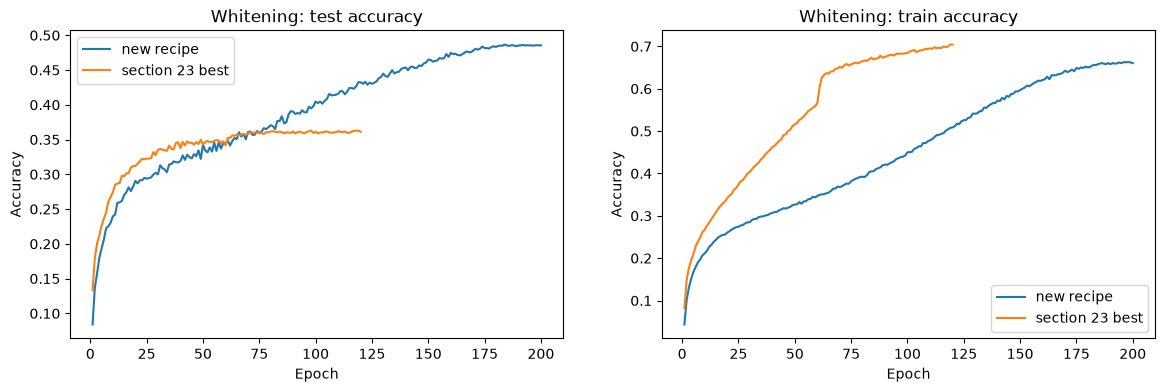

In [16]:
# compare with the best model without whitening (section 23: dropout=0.5, 120 epochs)
results["Whitening"]["section 23 best"] = results["Dropout (120 epochs)"]["dropout=0.5"]
compare("Whitening")

**Result:** the new recipe reaches **48.5%** test accuracy. That is 12.4% above the best model without whitening (36.1%) and above the 45% target.
- Train accuracy is 66%, lower than the 70% of the section 23 model, yet test accuracy is far higher. The gap between train and test accuracy shrinks from 34% to under 18%.
- Test loss ends at 2.04, compared with 2.77 for the section 23 model.

→ **Best model: 2 × 2048 GELU MLP with input whitening, random crop + flip, dropout = 0.2, lr = 0.05, weight decay = 5e-4, cosine schedule, 200 epochs (48.5%).**

## 26. Ablation: Which Ingredients Matter?
**Changed:** each run removes one ingredient of the new recipe (or sets it back to its old value).
**Fixed:** everything else in the recipe from section 25 (2 × 2048 hidden layers, GELU, dropout = 0.2, SGD + momentum 0.9, cosine schedule, 200 epochs).

In [17]:
# the full recipe is the run from section 25, so reuse it
results["Ablation"] = {"full recipe": results["Whitening"]["new recipe"]}

In [18]:
# no whitening: the plain MLP instead of WhitenedMLP
torch.manual_seed(0)
model = MLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
run_experiment("Ablation", "no whitening", model, optimizer, crop_dataloader, scheduler)

Ablation | no whitening | 10694756 parameters
Epoch  5 | train loss 3.7276, acc 0.1330 | test loss 3.8875, acc 0.1165
Epoch 10 | train loss 3.6989, acc 0.1407 | test loss 3.9549, acc 0.0998
Epoch 15 | train loss 3.6885, acc 0.1435 | test loss 3.9659, acc 0.1068
Epoch 20 | train loss 3.6775, acc 0.1480 | test loss 3.9324, acc 0.1127
Epoch 25 | train loss 3.6497, acc 0.1497 | test loss 4.0707, acc 0.0948
Epoch 30 | train loss 3.6335, acc 0.1521 | test loss 3.9274, acc 0.1111
Epoch 35 | train loss 3.6090, acc 0.1587 | test loss 3.8648, acc 0.1233
Epoch 40 | train loss 3.5798, acc 0.1607 | test loss 3.8568, acc 0.1258
Epoch 45 | train loss 3.5541, acc 0.1665 | test loss 3.8778, acc 0.1212
Epoch 50 | train loss 3.5134, acc 0.1719 | test loss 3.7867, acc 0.1414
Epoch 55 | train loss 3.4790, acc 0.1783 | test loss 3.7963, acc 0.1335
Epoch 60 | train loss 3.4437, acc 0.1844 | test loss 3.7829, acc 0.1363
Epoch 65 | train loss 3.3999, acc 0.1923 | test loss 3.8153, acc 0.1324
Epoch 70 | train l

In [19]:
# no random crop: horizontal flip only
flip_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
flip_data = datasets.CIFAR100(root="data", train=True, download=True, transform=flip_transform)
flip_dataloader = DataLoader(flip_data, batch_size=batch_size, shuffle=True,
                             num_workers=4, persistent_workers=True)

torch.manual_seed(0)
model = WhitenedMLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
run_experiment("Ablation", "no random crop", model, optimizer, flip_dataloader, scheduler)

Ablation | no random crop | 10694756 parameters
Epoch  5 | train loss 2.6234, acc 0.3516 | test loss 3.2250, acc 0.2436
Epoch 10 | train loss 1.2918, acc 0.6612 | test loss 3.4495, acc 0.2584
Epoch 15 | train loss 0.6359, acc 0.8277 | test loss 3.7723, acc 0.2587
Epoch 20 | train loss 0.4304, acc 0.8845 | test loss 3.8414, acc 0.2649
Epoch 25 | train loss 0.3477, acc 0.9110 | test loss 3.8224, acc 0.2667
Epoch 30 | train loss 0.3212, acc 0.9174 | test loss 3.8089, acc 0.2677
Epoch 35 | train loss 0.2983, acc 0.9264 | test loss 3.7984, acc 0.2723
Epoch 40 | train loss 0.2735, acc 0.9341 | test loss 3.8457, acc 0.2698
Epoch 45 | train loss 0.2684, acc 0.9363 | test loss 3.8210, acc 0.2761
Epoch 50 | train loss 0.2450, acc 0.9446 | test loss 3.8098, acc 0.2745
Epoch 55 | train loss 0.2368, acc 0.9476 | test loss 3.8121, acc 0.2772
Epoch 60 | train loss 0.2335, acc 0.9474 | test loss 3.8238, acc 0.2753
Epoch 65 | train loss 0.2158, acc 0.9544 | test loss 3.8438, acc 0.2735
Epoch 70 | train

In [20]:
# no weight decay
torch.manual_seed(0)
model = WhitenedMLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
run_experiment("Ablation", "no weight decay", model, optimizer, crop_dataloader, scheduler)

Ablation | no weight decay | 10694756 parameters
Epoch  5 | train loss 3.4505, acc 0.1738 | test loss 3.3035, acc 0.2137
Epoch 10 | train loss 3.2640, acc 0.2091 | test loss 3.2286, acc 0.2370
Epoch 15 | train loss 3.2769, acc 0.2110 | test loss 3.2554, acc 0.2414
Epoch 20 | train loss 3.3059, acc 0.2122 | test loss 3.3215, acc 0.2277
Epoch 25 | train loss 3.3156, acc 0.2129 | test loss 3.3949, acc 0.2215
Epoch 30 | train loss 3.3194, acc 0.2134 | test loss 3.4510, acc 0.2115
Epoch 35 | train loss 3.2981, acc 0.2177 | test loss 3.4603, acc 0.2136
Epoch 40 | train loss 3.2675, acc 0.2244 | test loss 3.4974, acc 0.1996
Epoch 45 | train loss 3.2503, acc 0.2296 | test loss 3.5094, acc 0.1988
Epoch 50 | train loss 3.2191, acc 0.2337 | test loss 3.5030, acc 0.2009
Epoch 55 | train loss 3.1830, acc 0.2406 | test loss 3.5103, acc 0.2036
Epoch 60 | train loss 3.1403, acc 0.2459 | test loss 3.4958, acc 0.2081
Epoch 65 | train loss 3.0856, acc 0.2602 | test loss 3.4993, acc 0.2072
Epoch 70 | trai

In [21]:
# the old learning rate (0.005 instead of 0.05)
torch.manual_seed(0)
model = WhitenedMLP(hidden_sizes=[2048, 2048], activation=nn.GELU, dropout=0.2).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
run_experiment("Ablation", "lr=0.005", model, optimizer, crop_dataloader, scheduler)

Ablation | lr=0.005 | 10694756 parameters
Epoch  5 | train loss 4.2881, acc 0.0560 | test loss 4.3343, acc 0.0518
Epoch 10 | train loss 3.8391, acc 0.1202 | test loss 3.9255, acc 0.1069
Epoch 15 | train loss 3.6580, acc 0.1509 | test loss 3.7159, acc 0.1444
Epoch 20 | train loss 3.5200, acc 0.1720 | test loss 3.5702, acc 0.1692
Epoch 25 | train loss 3.4031, acc 0.1916 | test loss 3.4501, acc 0.1933
Epoch 30 | train loss 3.3151, acc 0.2063 | test loss 3.3535, acc 0.2088
Epoch 35 | train loss 3.2321, acc 0.2193 | test loss 3.2758, acc 0.2226
Epoch 40 | train loss 3.1580, acc 0.2333 | test loss 3.2030, acc 0.2345
Epoch 45 | train loss 3.0919, acc 0.2462 | test loss 3.1464, acc 0.2450
Epoch 50 | train loss 3.0321, acc 0.2570 | test loss 3.0853, acc 0.2567
Epoch 55 | train loss 2.9699, acc 0.2697 | test loss 3.0367, acc 0.2682
Epoch 60 | train loss 2.9162, acc 0.2801 | test loss 2.9799, acc 0.2785
Epoch 65 | train loss 2.8683, acc 0.2884 | test loss 2.9323, acc 0.2889
Epoch 70 | train loss 

full recipe                      final train acc 0.6604 | final test acc 0.4854   <-- best
no whitening                     final train acc 0.6188 | final test acc 0.3597
no random crop                   final train acc 0.9941 | final test acc 0.2986
no weight decay                  final train acc 0.5104 | final test acc 0.3200
lr=0.005                         final train acc 0.3910 | final test acc 0.3649


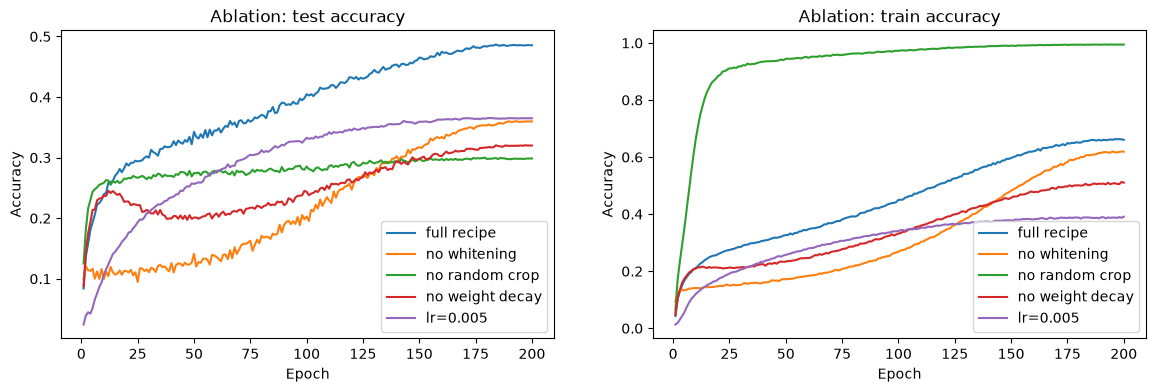

In [22]:
compare("Ablation")

**Result:** every ingredient is needed. Removing any one of them costs 12–19%.
- **No whitening (36.0%):** back to the level of the earlier models. Random crop, weight decay and the higher learning rate don't help on their own.
- **No random crop (29.9%):** the model memorises the training set (99.4% train accuracy). Whitening boosts fine detail, and without shifted copies of each image the MLP learns that detail by heart.
- **No weight decay (32.0%):** lr = 0.05 is too large without it, so the model learns slowly and unsteadily. This matches the learning rate sweep in section 10.
- **lr = 0.005 (36.5%):** the old learning rate is too small for whitened inputs. After 200 epochs the model is still underfitting (39% train accuracy).

This is why the one-at-a-time sweeps in sections 9–16 could not find this recipe. Whitening only pays off together with random crop, and section 16 had rejected random crop because it hurts the unwhitened model.

## 27. Final Result
**Best model: 48.5% test accuracy** (target: 45%).

| Stage | Section | Test accuracy |
|---|---|---|
| Baseline | 8 | 23.6% |
| Best settings from the sweeps, 40 epochs | 17 | 35.1% |
| Dropout = 0.5, 120 epochs | 23 | 36.1% |
| Whitening + random crop + lr = 0.05 with weight decay, 200 epochs | 25 | **48.5%** |

- The model is still a 2 × 2048 GELU MLP with 10,694,756 trainable parameters. The whitening layer is fixed and adds none.
